<a href="https://colab.research.google.com/github/maryammouaki/regression-models-exploration/blob/main/regression_maryamemouaki.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**TP Régression avec Python**
 : Mouaki maryam

Objectif
Ce TP consiste à construire, comparer et interpréter plusieurs modèles de régression tout en respectant un protocole expérimental sans fuite de données.

Les expériences portent sur :

les émissions de CO₂ ;
la consommation d'énergie ;
les prix immobiliers ;
les mesures corrélées ;
les indicateurs marketing ;
l'incertitude prédictive avec un petit échantillon.

In [ ]:
from pathlib import Path
import platform, json, hashlib, unittest
import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import skew, kurtosis, norm
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, BayesianRidge, RidgeCV
from sklearn.model_selection import (train_test_split, KFold, GridSearchCV,
                                     cross_val_score, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj.to_string() if isinstance(obj, (pd.DataFrame, pd.Series)) else obj)

SEED = 42
MODE_RAPIDE = True
REPETITIONS = 5 if MODE_RAPIDE else 20

versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
}
display(pd.Series(versions, name="Version exécutée"))
print("Réplications par scénario :", REPETITIONS)

,Version exécutée
python,3.13.16
numpy,2.1.3
pandas,2.2.3
scipy,1.16.3
scikit-learn,1.6.1
matplotlib,3.10.0


Réplications par scénario : 5


In [ ]:
FICHIER_REPERE = "vehicules_co2_brut.csv"
CANDIDATS = [Path("data"), Path("../data"), Path("/content/data"), Path("/content"),
             Path.home() / "Downloads" / "data", Path(".")]
DATA_DIR = next((p for p in CANDIDATS if (p / FICHIER_REPERE).exists()), None)
if DATA_DIR is None:
    for base in (Path("/content"), Path.cwd(), Path.home() / "Downloads"):
        trouves = list(base.rglob(FICHIER_REPERE)) if base.exists() else []
        if trouves:
            DATA_DIR = trouves[0].parent
            break
if DATA_DIR is None:
    raise FileNotFoundError(
        "Fichiers introuvables. Sous Colab : téléversez le dossier 'data' "
        "(les 10 CSV) dans /content, ou dézippez data.zip dans /content.")
print("Dossier de données :", DATA_DIR.resolve())

SORTIES = Path("sorties_regression")
FIGURES = SORTIES / "figures"
for d in (SORTIES, FIGURES):
    d.mkdir(parents=True, exist_ok=True)

def chemin(nom):
    return DATA_DIR / nom

def montrer(fig, nom):
    fig.tight_layout()
    fig.savefig(FIGURES / (nom + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

synthese = []
def suivre(cas, parametres, graine, n_train, n_test, note=""):
    synthese.append({"Cas": cas, "Paramètres": parametres, "Graine": graine,
                     "Train": n_train, "Test": n_test, "Note": note})

Dossier de données : /content


In [ ]:
SEED = 42
MODE_RAPIDE = True

Q1 Quelle grandeur cherche-t-on à prédire en régression ? Donnez un exemple de cible numérique et deux variables explicatives possibles.

-> En regression, on veut predire une grandeur numerique continue, la cible y, a partir d une ou plusieurs variables explicatives X. Exemple : predire le prix d une maison (cible numerique) a partir de la surface et du nombre de pieces.

Q2 Expliquez avec vos mots la différence entre entraînement, validation et test. À quel moment peut-on consulter le test ?

-> L entrainement ajuste les parametres du modele sur un premier jeu. La validation sert a comparer plusieurs modeles ou reglages pour choisir le meilleur, sur des donnees deja vues a l apprentissage. Le test evalue le modele final sur des donnees jamais utilisees. On regarde le test seulement a la fin, une seule fois, quand le modele est deja choisi.

Q3 Pourquoi faut-il ajuster l'imputation et la standardisation sur le train uniquement ? Décrivez une fuite de données possible.

-> L imputation (la mediane) et la standardisation (moyenne, ecart type) apprennent des statistiques. Si on les calcule sur tout le jeu, les statistiques du test contaminent l entrainement : c est une fuite de donnees (data leakage). Exemple : choisir les variables ou regler un hyperparametre en regardant le score de test, puis reutiliser ce meme test pour conclure, le score devient optimiste et pas representatif.

Q4 Relancez deux fois le même générateur avec la même graine, puis avec une autre. Qu'observez-vous ? Pourquoi conserver la graine et les versions des bibliothèques ?

-> Avec la meme graine on obtient exactement les memes donnees, donc les memes resultats : l experience est reproductible. Avec une autre graine l echantillon change et les scores varient. Garder la graine et les versions des bibliotheques permet de reproduire a l identique et de comparer equitablement.

Q5 Si plusieurs lignes concernent le même véhicule, quelle difficulté pose une séparation aléatoire ligne par ligne ? Et si les lignes représentent des dates successives ?

-> Si plusieurs lignes concernent le meme vehicule, une separation aleatoire peut mettre ce vehicule a la fois dans le train et dans le test (fuite par groupe) : il faut separer par groupes (GroupKFold / GroupShuffleSplit). Si les lignes sont des dates qui se suivent, la separation aleatoire detruit l ordre du temps : il faut couper par le temps, le passe en train et le futur en test (TimeSeriesSplit).

3. Générer, charger et contrôler les données
3.2 Nettoyer sans fuite d'information
Objectif Détecter les défauts d'un CSV et justifier chaque opération de nettoyage.

1. Exécutez la génération / le chargement du CSV vehicules_co2_brut.csv. Affichez head(), shape, dtypes, le nombre de valeurs manquantes par colonne, le nombre d'infinis et le nombre de doublons

In [ ]:
def make_linear_data(n=100, p=15, n_signal=5, noise=3.0, rho=0.0, seed=42):
    rng = np.random.default_rng(seed)
    common = rng.normal(size=(n, 1))
    X = np.sqrt(rho) * common + np.sqrt(1 - rho) * rng.normal(size=(n, p))
    beta = np.zeros(p)
    beta[:n_signal] = np.resize(np.array([4., -3., 2., 1.5, -2.]), n_signal)
    y = 10 + X @ beta + rng.normal(0, noise, n)
    return pd.DataFrame(X, columns=["x{:02d}".format(j + 1) for j in range(p)]).assign(y=y)

def make_curve(n=180, kind="energie", noise=40., seed=42):
    rng = np.random.default_rng(seed)
    if kind == "energie":
        x = rng.uniform(-5, 35, n); signal = 240 + 1.2 * (x - 18) ** 2
        names = ("temperature_c", "energie_mwh")
    elif kind == "immobilier":
        x = rng.uniform(30, 180, n); signal = 60 + 1.4 * x + .006 * (x - 90) ** 2
        names = ("surface_m2", "prix_k_eur")
    else:
        raise ValueError("kind doit être 'energie' ou 'immobilier'.")
    return pd.DataFrame({names[0]: x, names[1]: signal + rng.normal(0, noise, n)})

def make_bayes_data(n=200, rho=0.2, noise=4.0, seed=42):
    rng = np.random.default_rng(seed)
    p = 8
    common = rng.normal(size=(n, 1))
    X = np.sqrt(rho) * common + np.sqrt(1 - rho) * rng.normal(size=(n, p))
    beta = np.array([4., -3., 2., 1.5, -2., 4., -3., 2.])
    y = 10 + X @ beta + rng.normal(0, noise, n)
    return pd.DataFrame(X, columns=["x{:02d}".format(j + 1) for j in range(p)]).assign(y=y)

In [ ]:
def load_numeric_csv(filepath, target_col, feature_cols=None, drop_duplicates=True,
                     sep=",", decimal="."):
    frame = pd.read_csv(filepath, sep=sep, decimal=decimal)
    if target_col not in frame.columns:
        raise ValueError("Cible absente : {}".format(target_col))
    if feature_cols is None:
        feature_cols = [c for c in frame.columns if c != target_col]
    manquantes = [c for c in feature_cols if c not in frame.columns]
    if manquantes:
        raise ValueError("Colonnes d'entrée absentes : {}".format(manquantes))

    for c in frame.columns:
        if frame[c].dtype == object:
            frame[c] = pd.to_numeric(frame[c], errors="coerce")

    def audit(d):
        num = d.select_dtypes(include=np.number)
        return {
            "Nombre de lignes": len(d),
            "Cibles manquantes": int(d[target_col].isna().sum()),
            "Valeurs infinies": int(np.isinf(num).sum().sum()),
            "Doublons exacts": int(d.duplicated().sum()),
            "Entrées manquantes": int(d[feature_cols].isna().sum().sum()),
        }

    avant = audit(frame)
    propre = frame.copy()
    if drop_duplicates:
        propre = propre.drop_duplicates()
    propre = propre.replace([np.inf, -np.inf], np.nan)
    propre = propre.dropna(subset=[target_col])
    apres = audit(propre)
    return propre, avant, apres

In [ ]:
chemin_co2 = chemin("vehicules_co2_brut.csv")
vehicules_co2_brut = pd.read_csv(chemin_co2)

print(vehicules_co2_brut.head())
print("shape :", vehicules_co2_brut.shape)
print("dtypes :\n", vehicules_co2_brut.dtypes)
print("Manquants par colonne :\n", vehicules_co2_brut.isna().sum())
colonnes_num = vehicules_co2_brut.select_dtypes(include=np.number)
print("Infinis :", int(np.isinf(colonnes_num).sum().sum()))
print("Doublons :", int(vehicules_co2_brut.duplicated().sum()))

cible = "co2_g_km"
entrees = ["cylindree_l", "cylindres", "consommation_l_100km"]

df_co2, audit_avant, audit_apres = load_numeric_csv(
    chemin_co2, cible, entrees, drop_duplicates=True)

audit = pd.DataFrame({
    "Avant nettoyage": audit_avant,
    "Après nettoyage": audit_apres,
})
display(audit)
print("Extrait nettoyé :\n", df_co2.head())

   cylindree_l  cylindres  consommation_l_100km    co2_g_km
0     4.095824        8.0                   inf  258.908660
1     2.755514        6.0              8.470939         NaN
2     4.434392       10.0             11.285646  277.669167
3     3.789472        6.0             10.063367  235.396106
4     1.376709        NaN              4.968185  143.692232
shape : (401, 4)
dtypes :
 cylindree_l             float64
cylindres               float64
consommation_l_100km    float64
co2_g_km                float64
dtype: object
Manquants par colonne :
 cylindree_l             14
cylindres               18
consommation_l_100km    15
co2_g_km                 1
dtype: int64
Infinis : 1
Doublons : 1


,Avant nettoyage,Après nettoyage
Nombre de lignes,401,399
Cibles manquantes,1,0
Valeurs infinies,1,0
Doublons exacts,1,0
Entrées manquantes,47,48


Extrait nettoyé :
    cylindree_l  cylindres  consommation_l_100km    co2_g_km
0     4.095824        8.0                   NaN  258.908660
2     4.434392       10.0             11.285646  277.669167
3     3.789472        6.0             10.063367  235.396106
4     1.376709        NaN              4.968185  143.692232
5     4.902489       10.0             11.853482  294.965247


In [ ]:
imputer = SimpleImputer(strategy='median')

print("--- TEST 1 : valeur non numérique ---")
df_test1 = df_co2.copy()
df_test1['cylindree_l'] = df_test1['cylindree_l'].astype(object)
df_test1.loc[0, 'cylindree_l'] = "valeur_aberrante"
try:
    imputer.fit(df_test1)
    print("Succès (inattendu)")
except Exception as e:
    print("Erreur interceptée :", type(e).__name__)
    print("Message :", e)

print("\n--- TEST 2 : colonne entièrement manquante ---")
df_test2 = df_co2.copy()
df_test2['cylindree_l'] = np.nan
try:
    imp2 = SimpleImputer(strategy='median')
    df_t = imp2.fit_transform(df_test2)
    print("Forme d'origine :", df_test2.shape)
    print("Forme après transformation :", df_t.shape)
    print("Remarque : une colonne 100 % manquante est silencieusement ignorée (supprimée).")
except Exception as e:
    print("Erreur interceptée :", type(e).__name__, "-", e)

--- TEST 1 : valeur non numérique ---
Erreur interceptée : ValueError
Message : Cannot use median strategy with non-numeric data:
could not convert string to float: 'valeur_aberrante'

--- TEST 2 : colonne entièrement manquante ---
Forme d'origine : (399, 4)
Forme après transformation : (399, 3)
Remarque : une colonne 100 % manquante est silencieusement ignorée (supprimée).


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['cylindree_l']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


# Activité 2

Q6 Présentez chaque variable et son unité. Quelle erreur ferait-on en conservant la cible parmi les variables explicatives ?

->

co2_g_km : la cible a predire, en g/km.
cylindree_l : une entree, la cylindree en litres (L).
cylindres : une entree, le nombre de cylindres (sans unite).
consommation_l_100km : une entree, la consommation en L/100 km.
Garder la cible parmi les variables explicatives cree une fuite de donnees : le modele utiliserait la vraie valeur de co2_g_km pour la predire et ses scores deviendraient parfaits pour rien.

Q7 Expliquez l'évolution du nombre de lignes. Distinguez les lignes supprimées des valeurs simplement transformées en valeurs manquantes.

-> On passe de 401 a 399 lignes : une ligne est un doublon exact et une autre a une cible manquante, ces deux lignes sont supprimees par drop_duplicates() et dropna(subset=[cible]). La valeur infinie n a pas supprime de ligne, elle a ete transformee en valeur manquante (NaN), et la on passe les entrees manquantes de 47 a 48.

Q8 Pourquoi ne remplace-t-on pas une cible manquante par sa moyenne ? Pourquoi peut-on envisager une imputation pour une entrée manquante ?

-> La cible c est la verite qu on cherche a apprendre : l inventer avec sa moyenne fabrique une fausse etiquette et biaise l entrainement. Une entree manquante par contre peut etre imputee car la cible reste connue pour cette ligne : on garde la ligne et on estime juste la valeur manquante (mediane apprise sur le train).

Q9 À quel moment la médiane d'imputation est-elle calculée ? Expliquez comment vous compareriez mean et median sur les mêmes plis du train, sans utiliser le test pour choisir.

-> La mediane est calculee a l appel de pipeline.fit(...), donc sur le train uniquement, et dans chaque pli de validation. Pour comparer mean et median : utiliser les memes plis de validation croisee sur le train, calculer la RMSE moyenne par pli pour chaque strategie et garder la meilleure ; le test n est jamais regarde.

Q10 Introduisez une valeur non numérique, puis testez une colonne entièrement manquante, dans deux copies distinctes. Quelle erreur obtenez-vous ? Pourquoi vaut-il mieux interrompre le calcul que corriger silencieusement ces cas ?

-> La valeur non numerique declenche une ValueError (could not convert string to float). Une colonne entierement manquante ne leve pas d erreur : SimpleImputer l ignore sans rien dire (elle est supprimee), ce qui peut cacher un probleme de collecte. Mieux vaut arreter le calcul pour aller voir la donnee bizarre, plutot que de sortir un modele bati sur des donnees fausses.

Prolongement (3.3) : lire un CSV externe avec sep/decimal configurables et refuser le texte incompatible, voir la cellule d export en fin de notebook.



4. Les métriques et le pipeline commun
Objectif Calculer une erreur et l'interpréter dans la bonne unité.

1. Pour y = [1, 2, 3] et des prédictions [1, 2, 5], calculer les résidus puis les quatre métriques à la main. 2. Écrire une fonction personnelle calculer_metriques(y, prediction) et la comparer à regression_metrics au moyen de np.testing.assert_allclose. 3. Remplacer la dernière prédiction par 8 et recommencer.

In [ ]:
def regression_metrics(y_true, y_pred):
    y = np.asarray(y_true, dtype=float)
    pred = np.asarray(y_pred, dtype=float)
    if y.ndim != 1 or pred.shape != y.shape or y.size < 2:
        raise ValueError("Deux vecteurs 1D de même taille >= 2 sont requis.")
    if not np.isfinite(y).all() or not np.isfinite(pred).all():
        raise ValueError("Les valeurs réelles et prédites doivent être finies.")
    error = y - pred
    mse = float(np.mean(error ** 2))
    denom = float(np.sum((y - y.mean()) ** 2))
    r2 = float(1 - np.sum(error ** 2) / denom) if denom > 0 else float("nan")
    return {"MAE": float(np.mean(np.abs(error))), "MSE": mse,
            "RMSE": float(np.sqrt(mse)), "R2": r2}


def calculer_metriques(y, prediction):
    y = np.asarray(y, dtype=float)
    prediction = np.asarray(prediction, dtype=float)
    if y.ndim != 1 or prediction.shape != y.shape or y.size < 2:
        raise ValueError("Deux vecteurs 1D de même taille >= 2 sont requis.")
    if not np.isfinite(y).all() or not np.isfinite(prediction).all():
        raise ValueError("Les valeurs réelles et prédites doivent être finies.")
    residus = y - prediction
    mae = np.mean(np.abs(residus))
    mse = np.mean(residus ** 2)
    rmse = np.sqrt(mse)
    variance_y = np.mean((y - np.mean(y)) ** 2)
    r2 = 1 - (mse / variance_y) if variance_y != 0 else np.nan
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}


ref = regression_metrics([1, 2, 3], [1, 2, 5])
perso = calculer_metriques([1, 2, 3], [1, 2, 5])
np.testing.assert_allclose(list(perso.values()), list(ref.values()))
print("Les deux fonctions coïncident :", {k: round(v, 4) for k, v in perso.items()})

Les deux fonctions coïncident : {'MAE': np.float64(0.6667), 'MSE': np.float64(1.3333), 'RMSE': np.float64(1.1547), 'R2': np.float64(-1.0)}


In [ ]:
y_true = [1, 2, 3]
resultats_metriques = []
for nom, pred in [("Prédiction [1, 2, 5]", [1, 2, 5]),
                  ("Prédiction [1, 2, 8]", [1, 2, 8])]:
    m = calculer_metriques(y_true, pred)
    resultats_metriques.append({"Expérience": nom, **{k: round(v, 4) for k, v in m.items()}})
tableau_metriques = pd.DataFrame(resultats_metriques)
display(tableau_metriques)

,Expérience,MAE,MSE,RMSE,R2
0,"Prédiction [1, 2, 5]",0.6667,1.3333,1.1547,-1.0
1,"Prédiction [1, 2, 8]",1.6667,8.3333,2.8868,-11.5


Q11 Présentez le calcul de MAE, MSE, RMSE et R² pour le premier exemple. Si la cible est en g/km, quelle est l'unité de chaque métrique ?

-> Cas 1 (pred = [1, 2, 5]) : les residus valent (0, 0, -2).

MAE = (0 + 0 + 2)/3 = 0,667 MSE = (0 + 0 + 4)/3 = 1,333 RMSE = racine de 1,333 = 1,155 R2 = 1 - (4/3)/(2/3) = 1 - 2 = -1,000 (la moyenne du test vaut 2, la variance 2/3). Unites : MAE et RMSE en g/km, MSE en (g/km) au carre, R2 sans unite.

Q12 Lorsque la dernière prédiction passe de 5 à 8, comment évoluent MAE et RMSE ? Quelle métrique réagit davantage aux grandes erreurs ?

-> La MAE passe de 0,667 a 1,667 et la RMSE de 1,155 a 2,887. C est la RMSE (et la MSE) qui bouge le plus car l erreur est mise au carre : l ecart de 3 sur un point pese beaucoup plus.

Q13 Un R² négatif signale-t-il nécessairement une erreur de programmation ? Donnez une interprétation précise. Expliquez aussi le cas d'une cible constante.

-> Non. Un R2 negatif (ici -1) veut juste dire que le modele fait pire que predire tout le temps la moyenne du jeu evalue. Si la cible est constante, la variance au denominateur est nulle : le R2 n est pas defini et la fonction renvoie NaN.

Q14 Que prédit DummyRegressor(strategy="mean") après apprentissage ? Quelle moyenne utilise-t-il ? Pourquoi le conserver comme référence ?

-> Il predit une constante egale a la moyenne de la cible calculee sur le train. C est le modele naif de reference : tout modele utile doit au moins faire mieux que lui

In [ ]:
y = [1, 2, 3]
prediction = [1, 2, 5]

resultat_perso = calculer_metriques(y, prediction)
resultat_reference = regression_metrics(y, prediction)

for metrique in ["MAE", "MSE", "RMSE", "R2"]:
    np.testing.assert_allclose(
        resultat_perso[metrique],
        resultat_reference[metrique],
        equal_nan=True
    )

print("Les deux fonctions donnent les mêmes résultats.")
print(resultat_perso)

Les deux fonctions donnent les mêmes résultats.
{'MAE': np.float64(0.6666666666666666), 'MSE': np.float64(1.3333333333333333), 'RMSE': np.float64(1.1547005383792515), 'R2': np.float64(-1.0)}


In [ ]:
prediction_5 = [1, 2, 5]
prediction_8 = [1, 2, 8]

resultats = pd.DataFrame([
    {"Dernière prédiction": 5, **calculer_metriques(y, prediction_5)},
    {"Dernière prédiction": 8, **calculer_metriques(y, prediction_8)}
])

display(resultats.round(4))

,Dernière prédiction,MAE,MSE,RMSE,R2
0,5,0.6667,1.3333,1.1547,-1.0
1,8,1.6667,8.3333,2.8868,-11.5


In [ ]:
X_co2 = df_co2[entrees]
y_co2 = df_co2[cible]

X_train, X_test, y_train, y_test = train_test_split(
    X_co2, y_co2, test_size=0.2, random_state=42)
suivre("CO₂", "3 facteurs", SEED, len(X_train), len(X_test), "g/km")
print("Train :", len(X_train), "| Test :", len(X_test))
print("Intersection des indices :", len(set(X_train.index) & set(X_test.index)))

Train : 319 | Test : 80
Intersection des indices : 0


In [ ]:
modele_moyenne = DummyRegressor(strategy="mean").fit(X_train, y_train)
pred_moyenne = modele_moyenne.predict(X_test)

pipe_1 = Pipeline([("imputer", SimpleImputer(strategy="median")),
                   ("lr", LinearRegression())]).fit(X_train[["cylindree_l"]], y_train)
pred_1 = pipe_1.predict(X_test[["cylindree_l"]])

pipe_3 = Pipeline([("imputer", SimpleImputer(strategy="median")),
                   ("lr", LinearRegression())]).fit(X_train, y_train)
pred_3 = pipe_3.predict(X_test)

def ligne_modele(nom, y_vrai, y_pred):
    m = regression_metrics(y_vrai, y_pred)
    return {"Modèle": nom, "MAE en g/km": m["MAE"], "RMSE en g/km": m["RMSE"], "R²": m["R2"]}

tableau_co2 = pd.DataFrame([
    ligne_modele("Moyenne du train", y_test, pred_moyenne),
    ligne_modele("Cylindrée seule", y_test, pred_1),
    ligne_modele("Trois facteurs", y_test, pred_3),
])
display(tableau_co2.round(4))
reduction = (tableau_co2.loc[1, "MAE en g/km"] - tableau_co2.loc[2, "MAE en g/km"]) \
            / tableau_co2.loc[1, "MAE en g/km"] * 100
print("Réduction relative de MAE (multiple vs cylindrée seule) : {:.1f} %".format(reduction))

,Modèle,MAE en g/km,RMSE en g/km,R²
0,Moyenne du train,47.3579,54.6502,-0.0012
1,Cylindrée seule,15.5462,20.5398,0.8586
2,Trois facteurs,11.4318,15.8491,0.9158


Réduction relative de MAE (multiple vs cylindrée seule) : 26.5 %


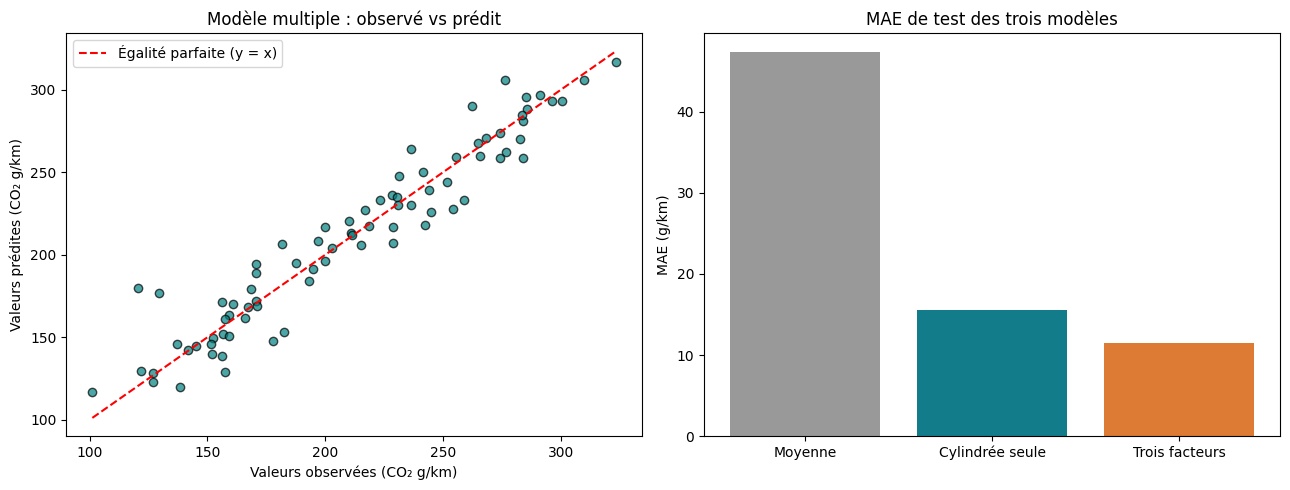

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, pred_3, alpha=0.7, color="teal", edgecolors="k")
borne = [min(y_test.min(), pred_3.min()), max(y_test.max(), pred_3.max())]
axes[0].plot(borne, borne, "r--", label="Égalité parfaite (y = x)")
axes[0].set_xlabel("Valeurs observées (CO₂ g/km)")
axes[0].set_ylabel("Valeurs prédites (CO₂ g/km)")
axes[0].set_title("Modèle multiple : observé vs prédit")
axes[0].legend()

axes[1].bar(["Moyenne", "Cylindrée seule", "Trois facteurs"],
            tableau_co2["MAE en g/km"], color=["#999", "#137C8B", "#DD7A34"])
axes[1].set_ylabel("MAE (g/km)")
axes[1].set_title("MAE de test des trois modèles")
montrer(fig, "co2_mae")

In [ ]:
rng = np.random.default_rng(SEED)
X_train_alea = X_train.copy()
X_test_alea = X_test.copy()
X_train_alea["variable_aleatoire"] = rng.normal(size=len(X_train))
X_test_alea["variable_aleatoire"] = rng.normal(size=len(X_test))

pipe_3_alea = Pipeline([("imputer", SimpleImputer(strategy="median")),
                        ("lr", LinearRegression())]).fit(X_train_alea, y_train)
pred_3_alea = pipe_3_alea.predict(X_test_alea)
print("Sans variable aléatoire :", {k: round(v, 3) for k, v in regression_metrics(y_test, pred_3).items()})
print("Avec variable aléatoire :", {k: round(v, 3) for k, v in regression_metrics(y_test, pred_3_alea).items()})

Sans variable aléatoire : {'MAE': 11.432, 'MSE': 251.193, 'RMSE': 15.849, 'R2': 0.916}
Avec variable aléatoire : {'MAE': 11.356, 'MSE': 246.503, 'RMSE': 15.7, 'R2': 0.917}


,CO₂
Moyenne,212.458021
Écart-type,55.536239
Asymétrie,-0.093821
Excès de kurtosis,-0.889792


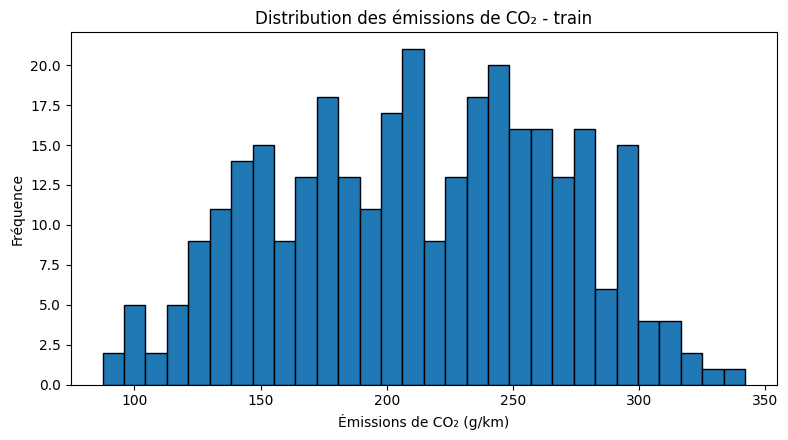

In [ ]:
y_train_arr = np.asarray(y_train).ravel()
statistiques = pd.Series({
    "Moyenne": np.mean(y_train_arr),
    "Écart-type": np.std(y_train_arr, ddof=1),
    "Asymétrie": skew(y_train_arr, bias=False),
    "Excès de kurtosis": kurtosis(y_train_arr, bias=False, fisher=True),
})
display(statistiques.to_frame("CO₂"))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(y_train_arr, bins=30, edgecolor="black")
ax.set_xlabel("Émissions de CO₂ (g/km)"); ax.set_ylabel("Fréquence")
ax.set_title("Distribution des émissions de CO₂ - train")
montrer(fig, "co2_hist")

Q15 Combien d'observations contient chaque sous-ensemble ? Vérifiez que les indices du train et du test ne se recouvrent pas.

-> 399 lignes nettoyees : 319 pour le train (80 %) et 80 pour le test (20 %). L intersection des indices du train et du test est vide (train_test_split fait des partitions disjointes).

Q16 Quel modèle donne ici la plus faible MAE ? Calculez la réduction relative de MAE du modèle multiple par rapport au modèle simple et l'exprimer en pourcentage.

-> Le modele a trois facteurs donne la plus faible MAE (11,43 g/km contre 15,55 pour la cylindree seule). Reduction = (15,55 - 11,43)/15,55 = environ 26,5 %.

Q17 — Pourquoi comparer les modèles sur des coupures différentes rendrait-il la conclusion moins fiable ?

Si les coupures (train/test) étaient différentes, les variations de performance seraient dues au hasard de l'échantillonnage des données d'un sous-ensemble à l'autre plutôt qu'à la réelle efficacité des modèles. Tous les modèles doivent être évalués sur le même jeu de test rigoureusement identique pour assurer une comparaison équitable et non biaisée.

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
resultats_cv = []
for variable in entrees:
    modele = Pipeline([("imputer", SimpleImputer(strategy="median")),
                       ("lr", LinearRegression())])
    scores = cross_validate(modele, X_train[[variable]], y_train, cv=cv,
                            scoring={"MAE": "neg_mean_absolute_error",
                                     "RMSE": "neg_root_mean_squared_error",
                                     "R2": "r2"})
    resultats_cv.append({"Variable": variable,
                         "MAE moyenne": -scores["test_MAE"].mean(),
                         "RMSE moyenne": -scores["test_RMSE"].mean(),
                         "R² moyen": scores["test_R2"].mean()})
tableau_resultats = pd.DataFrame(resultats_cv)

tableau_distribution = pd.DataFrame([
    {"Variable": v,
     "Asymétrie": skew(np.asarray(X_train[v]).ravel(), bias=False, nan_policy="omit"),
     "Excès de kurtosis": kurtosis(np.asarray(X_train[v]).ravel(), bias=False,
                                   fisher=True, nan_policy="omit")}
    for v in entrees])
tableau_distribution["RMSE de validation"] = tableau_resultats["RMSE moyenne"].values
display(tableau_distribution.round(3))

,Variable,Asymétrie,Excès de kurtosis,RMSE de validation
0,cylindree_l,-0.030,-1.272,21.067
1,cylindres,-0.092,-1.021,26.480
2,consommation_l_100km,-0.107,-0.948,16.707


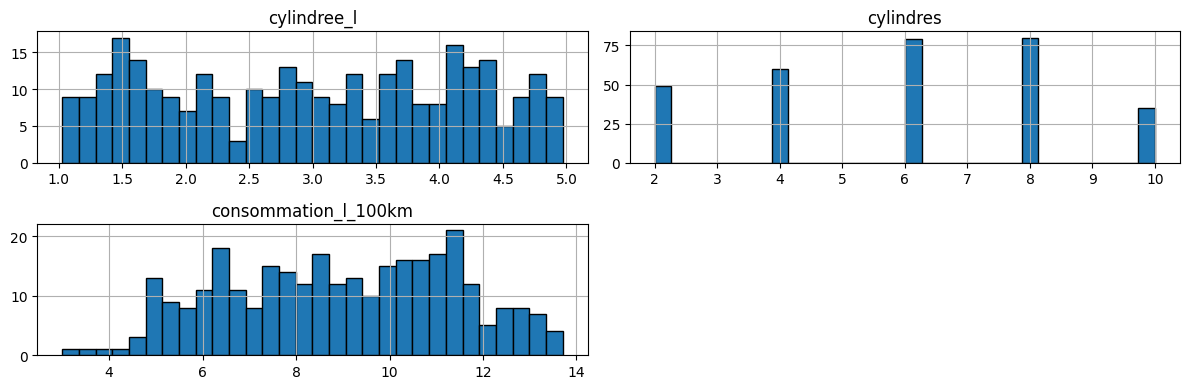

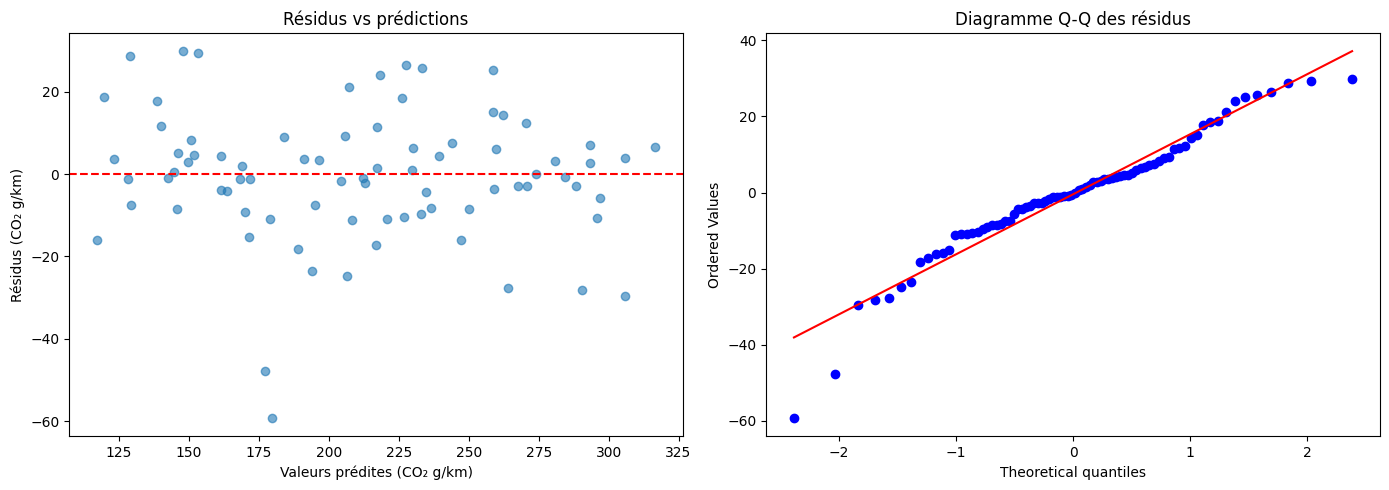

In [ ]:
X_train[entrees].hist(figsize=(12, 4), bins=30, edgecolor="black")
montrer(plt.gcf(), "co2_hist_entrees")

residus = np.asarray(y_test).ravel() - np.asarray(pred_3).ravel()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(pred_3, residus, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Valeurs prédites (CO₂ g/km)")
axes[0].set_ylabel("Résidus (CO₂ g/km)")
axes[0].set_title("Résidus vs prédictions")
stats.probplot(residus, dist="norm", plot=axes[1])
axes[1].set_title("Diagramme Q-Q des résidus")
montrer(fig, "co2_residus")

In [ ]:
df_energie = pd.read_csv(chemin("energie_temperature.csv"))
X_e = df_energie[["temperature_c"]]
y_e = df_energie["energie_mwh"]
X_e_train, X_e_test, y_e_train, y_e_test = train_test_split(
    X_e, y_e, test_size=0.25, random_state=42)
suivre("Énergie", "degrés 1-6", SEED, len(X_e_train), len(X_e_test), "MWh")

kf = KFold(n_splits=5, shuffle=True, random_state=42)
resultats_degres = []
for degre in range(1, 7):
    modele = Pipeline([("scaler", StandardScaler()),
                       ("poly", PolynomialFeatures(degree=degre, include_bias=False)),
                       ("lr", LinearRegression())])
    scores = -cross_val_score(modele, X_e_train, y_e_train, cv=kf,
                              scoring="neg_root_mean_squared_error")
    resultats_degres.append({"Degré": degre, "RMSE de validation": scores.mean(),
                             "Dispersion des plis": scores.std()})
df_cv_e = pd.DataFrame(resultats_degres)
display(df_cv_e.round(3))

meilleur_degre = int(df_cv_e.loc[df_cv_e["RMSE de validation"].idxmin(), "Degré"])
print("Degré retenu par la validation :", meilleur_degre)

def modele_polynomial(degre):
    return Pipeline([("scaler", StandardScaler()),
                     ("poly", PolynomialFeatures(degree=degre, include_bias=False)),
                     ("lr", LinearRegression())])

modele_e = modele_polynomial(meilleur_degre).fit(X_e_train, y_e_train)
pred_e = modele_e.predict(X_e_test)
pred_e_droite = modele_polynomial(1).fit(X_e_train, y_e_train).predict(X_e_test)

tableau_energie = pd.DataFrame([
    {"Modèle": "Droite de référence", **regression_metrics(y_e_test, pred_e_droite)},
    {"Modèle": "Polynomial degré {}".format(meilleur_degre),
     **regression_metrics(y_e_test, pred_e)},
])
display(tableau_energie.round(3))

,Degré,RMSE de validation,Dispersion des plis
0,1,150.956,20.217
1,2,39.906,1.813
2,3,40.183,1.748
3,4,40.013,1.351
4,5,39.665,1.617
5,6,40.136,1.682


Degré retenu par la validation : 5


,Modèle,MAE,MSE,RMSE,R2
0,Droite de référence,145.288,27236.790,165.036,0.109
1,Polynomial degré 5,33.782,1761.443,41.970,0.942


Après déstandardisation, les coefficients du modèle sont exprimés dans les unités d’origine. Le coefficient de la cylindrée est de 10,8369 g/km par litre, celui du nombre de cylindres est de 4,1902 g/km par cylindre, et celui de la consommation est de 13,8767 g/km par L/100 km, toutes les autres variables étant maintenues constantes. L’intercept est de 30,8899 g/km.

Ces coefficients décrivent les relations apprises par le modèle et ne prouvent pas nécessairement des relations de causalité.

Q20 : ajouter une variable aléatoire et observer son effet sur la prédiction.

L’objectif est de vérifier si ajouter une variable explicative améliore forcément un modèle. Ici, nous allons créer une variable aléatoire indépendante des émissions de CO₂, puis comparer les résultats sur le même jeu de test.

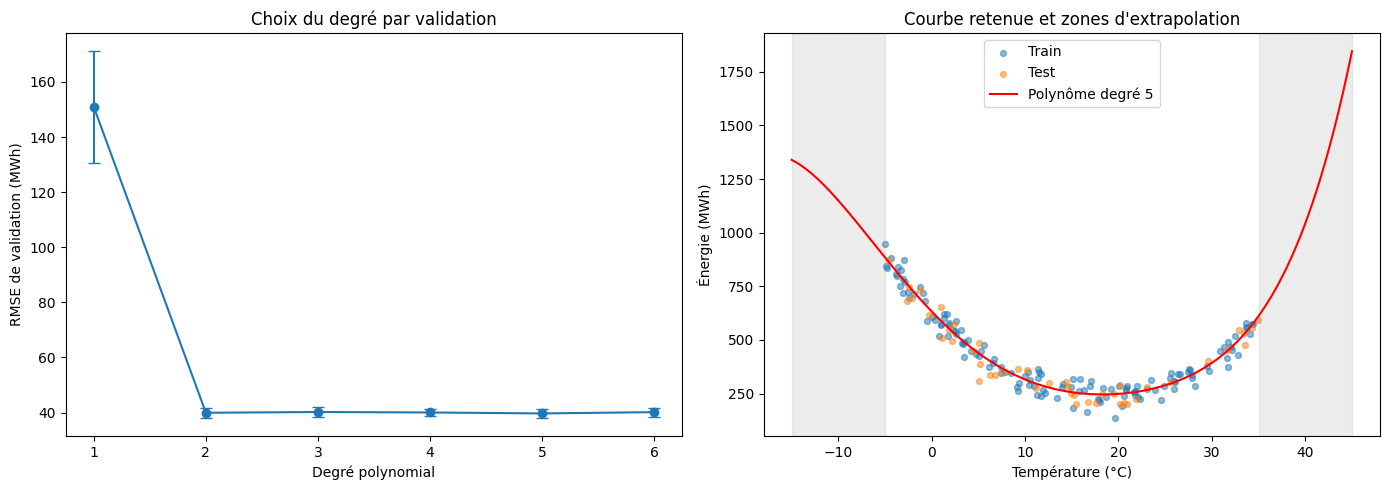

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].errorbar(df_cv_e["Degré"], df_cv_e["RMSE de validation"],
                 yerr=df_cv_e["Dispersion des plis"], marker="o", capsize=4)
axes[0].set_xlabel("Degré polynomial"); axes[0].set_ylabel("RMSE de validation (MWh)")
axes[0].set_title("Choix du degré par validation")

grille = pd.DataFrame({"temperature_c": np.linspace(-15, 45, 400)})
axes[1].scatter(X_e_train["temperature_c"], y_e_train, s=18, alpha=0.5, label="Train")
axes[1].scatter(X_e_test["temperature_c"], y_e_test, s=18, alpha=0.5, label="Test")
axes[1].plot(grille["temperature_c"], modele_e.predict(grille), color="red",
             label="Polynôme degré {}".format(meilleur_degre))
axes[1].axvspan(-15, -5, color="grey", alpha=0.15)
axes[1].axvspan(35, 45, color="grey", alpha=0.15)
axes[1].set_xlabel("Température (°C)"); axes[1].set_ylabel("Énergie (MWh)")
axes[1].set_title("Courbe retenue et zones d'extrapolation")
axes[1].legend()
montrer(fig, "energie_polynome")

In [ ]:
df_train_30 = pd.read_csv(chemin("immobilier_train.csv"))
df_diag = pd.read_csv(chemin("immobilier_diagnostic.csv"))
df_train_100 = make_curve(n=100, kind="immobilier", noise=25, seed=SEED + 20)

X_30, y_30 = df_train_30[["surface_m2"]], df_train_30["prix_k_eur"]
X_diag, y_diag = df_diag[["surface_m2"]], df_diag["prix_k_eur"]
X_100, y_100 = df_train_100[["surface_m2"]], df_train_100["prix_k_eur"]
suivre("Immobilier", "degrés 1-10", SEED + 20, 30, 1000, "k€ diagnostic")

def evaluer_modele(X_tr, y_tr, X_nouveau, y_nouveau, degre):
    modele = Pipeline([("scaler", StandardScaler()),
                       ("poly", PolynomialFeatures(degree=degre, include_bias=False)),
                       ("lr", LinearRegression())]).fit(X_tr, y_tr)
    rmse_tr = np.sqrt(mean_squared_error(y_tr, modele.predict(X_tr)))
    rmse_n = np.sqrt(mean_squared_error(y_nouveau, modele.predict(X_nouveau)))
    return modele, rmse_tr, rmse_n

resultats_7 = []
for taille, X_tr, y_tr in [(30, X_30, y_30), (100, X_100, y_100)]:
    for degre in range(1, 11):
        _, rmse_tr, rmse_n = evaluer_modele(X_tr, y_tr, X_diag, y_diag, degre)
        resultats_7.append({"Taille du train": taille, "Degré": degre,
                            "RMSE du train": rmse_tr, "RMSE du jeu neuf": rmse_n})
df_7 = pd.DataFrame(resultats_7)
display(df_7.round(2).pivot(index="Degré", columns="Taille du train",
                            values=["RMSE du train", "RMSE du jeu neuf"]))

RMSE du train        RMSE du jeu neuf       
Taille du train           30     100              30     100
Degré                                                       
1                       23.11  23.95            26.92  26.71
2                       22.03  22.32            25.32  24.80
3                       20.92  22.24            28.09  24.75
4                       20.16  21.91            26.69  25.78
5                       20.03  21.63            27.27  25.87
6                       19.99  21.62            26.92  25.93
7                       19.06  21.62            44.78  25.95
8                       17.63  21.58            51.40  26.05
9                       15.81  21.57           142.43  26.75
10                      15.80  21.56           128.83  28.42

Après l’ajout d’une variable aléatoire indépendante de la cible, la MAE passe de 11,432 à 11,356 g/km et la RMSE de 15,849 à 15,700 g/km. Le coefficient de détermination R² passe de 0,916 à 0,917.

Les performances s’améliorent légèrement sur ce jeu de test, mais cette amélioration peut être due au hasard. On ne peut donc pas affirmer que toute variable supplémentaire améliore la prédiction. Une variable non pertinente peut ajouter du bruit et favoriser le surapprentissage.

Conclusion générale : La comparaison montre que le modèle à trois facteurs est le plus performant parmi les trois modèles initiaux. Sa MAE est de 11,432 g/km, contre 15,546 g/km pour la régression utilisant uniquement la cylindrée, soit une réduction de 26,47 % (4,114 g/km). Son R² atteint 0,916.

Le nuage de points montre que la plupart des prédictions sont proches des valeurs observées, malgré quelques erreurs importantes. L’ajout d’une variable aléatoire améliore légèrement les métriques sur ce test, mais ce résultat peut être dû au hasard. Une limite de cette simulation est que l’évaluation repose sur une seule séparation train/test : d’autres séparations ou une validation croisée seraient nécessaires pour vérifier la stabilité des performances.

Activité 5 — Examiner les distributions

L’objectif est de calculer, pour les variables CO₂, la moyenne, l’écart-type, l’asymétrie et l’excès de kurtosis, uniquement sur les données d’entraînement

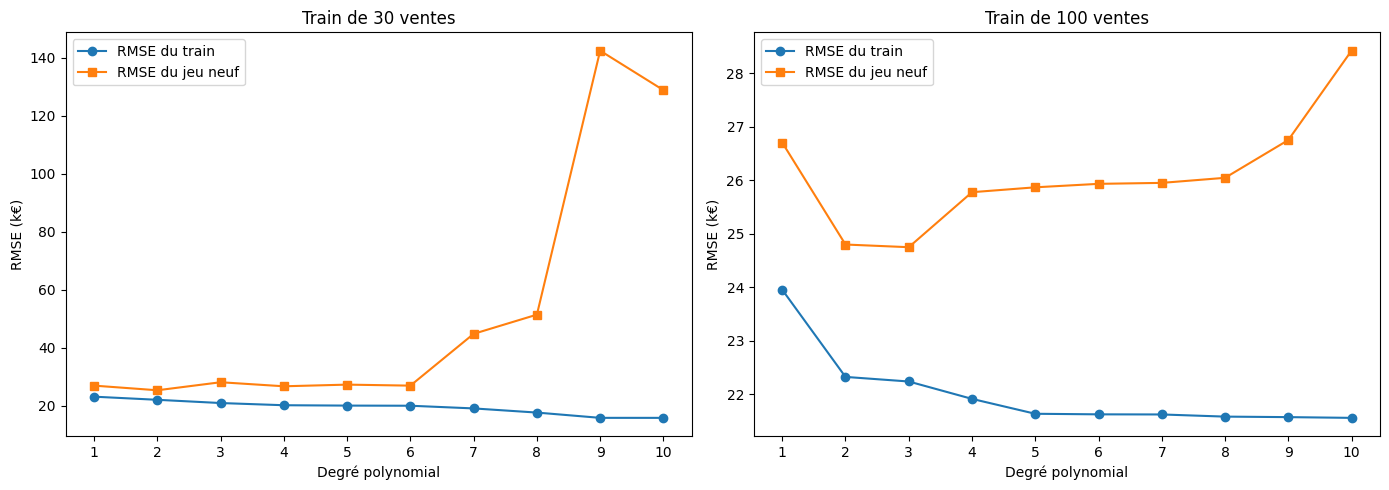

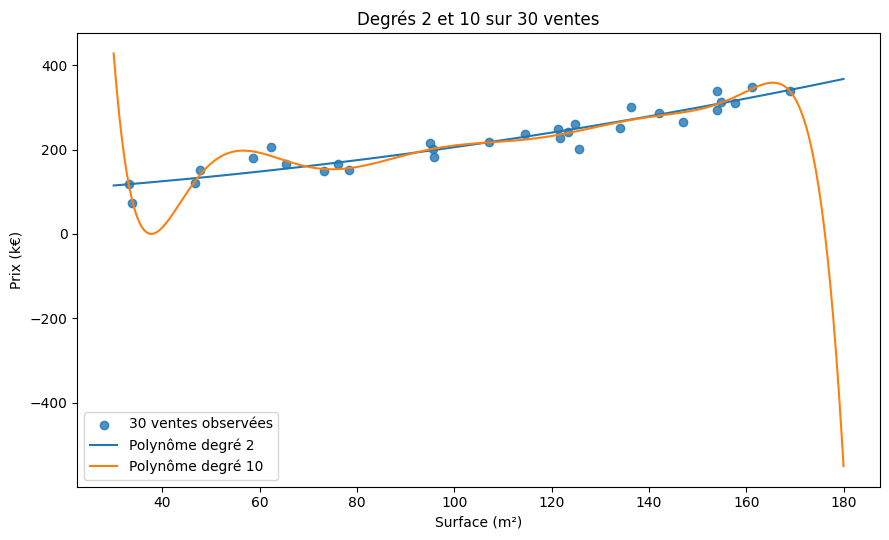

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, taille in zip(axes, [30, 100]):
    sous = df_7[df_7["Taille du train"] == taille]
    ax.plot(sous["Degré"], sous["RMSE du train"], marker="o", label="RMSE du train")
    ax.plot(sous["Degré"], sous["RMSE du jeu neuf"], marker="s", label="RMSE du jeu neuf")
    ax.set_title("Train de {} ventes".format(taille))
    ax.set_xlabel("Degré polynomial"); ax.set_ylabel("RMSE (k€)")
    ax.set_xticks(range(1, 11)); ax.legend()
montrer(fig, "immo_surajustement")

grille = pd.DataFrame({"surface_m2": np.linspace(30, 180, 500)})
modele_2 = evaluer_modele(X_30, y_30, X_diag, y_diag, 2)[0]
modele_10 = evaluer_modele(X_30, y_30, X_diag, y_diag, 10)[0]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(X_30["surface_m2"], y_30, label="30 ventes observées", alpha=0.8)
ax.plot(grille["surface_m2"], modele_2.predict(grille), label="Polynôme degré 2")
ax.plot(grille["surface_m2"], modele_10.predict(grille), label="Polynôme degré 10")
ax.set_xlabel("Surface (m²)"); ax.set_ylabel("Prix (k€)")
ax.set_title("Degrés 2 et 10 sur 30 ventes"); ax.legend()
montrer(fig, "immo_deg2_deg10")

Première interprétation des résultats

Cylindrée : asymétrie de −0,030, donc distribution presque symétrique.

Cylindres : asymétrie de −0,092, très légèrement orientée vers les petites valeurs.

Consommation : asymétrie de −0,107, c’est l’asymétrie la plus marquée parmi les quatre variables, mais elle reste faible.

CO₂ : asymétrie de −0,094, elle aussi faible.

Les quatre valeurs d’excès de kurtosis sont négatives. Cela suggère des distributions plus aplaties ou des queues moins lourdes que celles d’une loi normale, sans suffire à conclure sur leur forme exacte.

In [ ]:
df_ridge_train = pd.read_csv(chemin("ridge_train.csv"))
df_ridge_test = pd.read_csv(chemin("ridge_test.csv"))
vars_ridge = [c for c in df_ridge_train.columns if c != "y"]
toutes_vars_ridge = vars_ridge
X_rt, y_rt = df_ridge_train[vars_ridge], df_ridge_train["y"]
X_re, y_re = df_ridge_test[vars_ridge], df_ridge_test["y"]
suivre("Ridge", "OLs vs Ridge", SEED, len(X_rt), len(X_re), "unités simulées")

print("Corrélation moyenne hors diagonale (train) : {:.3f}".format(
    df_ridge_train[vars_ridge].corr().values[~np.eye(len(vars_ridge), dtype=bool)].mean()))

ols = Pipeline([("scaler", StandardScaler()), ("lr", LinearRegression())]).fit(X_rt, y_rt)
ridge_recherche = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("ridge", Ridge())]),
    {"ridge__alpha": np.logspace(-3, 3, 25)},
    scoring="neg_root_mean_squared_error",
    cv=KFold(5, shuffle=True, random_state=SEED)).fit(X_rt, y_rt)
alpha_ridge = ridge_recherche.best_params_["ridge__alpha"]

tableau_ridge = pd.DataFrame([
    {"Modèle": "OLS", **regression_metrics(y_re, ols.predict(X_re))},
    {"Modèle": "Ridge (alpha={:.3g})".format(alpha_ridge),
     **regression_metrics(y_re, ridge_recherche.predict(X_re))},
])
display(tableau_ridge.round(4))
gain_r = (tableau_ridge.loc[0, "RMSE"] - tableau_ridge.loc[1, "RMSE"]) / tableau_ridge.loc[0, "RMSE"] * 100
print("Alpha retenu : {:.4g} | gain relatif de RMSE (Ridge vs OLS) : {:.1f} %".format(alpha_ridge, gain_r))

Corrélation moyenne hors diagonale (train) : 0.976


,Modèle,MAE,MSE,RMSE,R2
0,OLS,3.1851,15.4663,3.9327,0.0326
1,Ridge (alpha=5.62),2.5212,9.9524,3.1547,0.3775


Alpha retenu : 5.623 | gain relatif de RMSE (Ridge vs OLS) : 19.8 %


Étendue : Les émissions de CO2 varient globalement de 90 g/km à plus de 340 g/km. Concentration : La majorité des véhicules se situent entre 150 g/km et 280 g/km. Diversité (pics) : On observe plusieurs pics (notamment autour de 150-160 g/km et 210 g/km), ce qui montre qu'il y a plusieurs catégories de véhicules dans le jeu de données (des citadines plus propres et des véhicules plus lourds ou puissants).

Nous allons entraîner une régression linéaire avec une seule variable à la fois. Chaque variable sera évaluée sur exactement les mêmes plis, uniquement dans les données d’entraînement

Dispersion moyenne des coefficients OLS   : 0.7314
Dispersion moyenne des coefficients Ridge : 0.0807


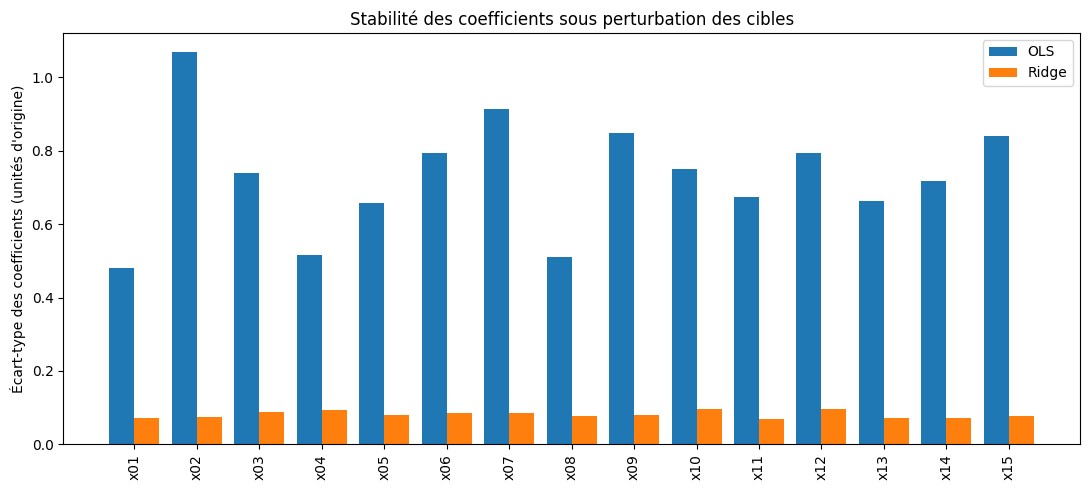

In [ ]:
def coefficients_perturbes(type_modele, alpha=1.0, rep=50):
    generateur = np.random.default_rng(SEED)
    valeurs = []
    for _ in range(rep):
        y_perturbe = y_rt + generateur.normal(0, 0.5, len(y_rt))
        if type_modele == "ols":
            modele = Pipeline([("scaler", StandardScaler()),
                               ("lr", LinearRegression())]).fit(X_rt, y_perturbe)
            coef = modele.named_steps["lr"].coef_
            echelle = modele.named_steps["scaler"].scale_
        else:
            modele = Pipeline([("scaler", StandardScaler()),
                               ("ridge", Ridge(alpha=alpha))]).fit(X_rt, y_perturbe)
            coef = modele.named_steps["ridge"].coef_
            echelle = modele.named_steps["scaler"].scale_
        valeurs.append(coef / echelle)
    return np.array(valeurs)

stab_ols = coefficients_perturbes("ols").std(axis=0)
stab_ridge = coefficients_perturbes("ridge", alpha_ridge).std(axis=0)
print("Dispersion moyenne des coefficients OLS   : {:.4f}".format(stab_ols.mean()))
print("Dispersion moyenne des coefficients Ridge : {:.4f}".format(stab_ridge.mean()))

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(np.arange(len(vars_ridge)) - 0.2, stab_ols, width=0.4, label="OLS")
ax.bar(np.arange(len(vars_ridge)) + 0.2, stab_ridge, width=0.4, label="Ridge")
ax.set_xticks(range(len(vars_ridge))); ax.set_xticklabels(vars_ridge, rotation=90)
ax.set_ylabel("Écart-type des coefficients (unités d'origine)")
ax.set_title("Stabilité des coefficients sous perturbation des cibles"); ax.legend()
montrer(fig, "ridge_stabilite")

Q21 — Quelle variable présente l’asymétrie la plus marquée ?

La consommation présente l’asymétrie la plus marquée parmi les quatre variables, avec une valeur de −0,107. Cette asymétrie est négative, ce qui indique une légère tendance vers une queue plus étendue du côté des petites valeurs. Cependant, sa valeur étant proche de zéro, l’asymétrie reste faible. L’histogramme permet de compléter cette interprétation visuelle.

Q22 — Que suggère un excès de kurtosis positif ?

Un excès de kurtosis positif peut suggérer des queues plus lourdes et davantage de valeurs extrêmes que pour une loi normale. Toutefois, cela ne prouve pas qu’il existe des erreurs de mesure : ces valeurs peuvent être réelles. Ce critère ne suffit pas non plus pour supprimer une variable, car sa pertinence dépend notamment de sa capacité à prédire la cible. Dans mes résultats, les excès de kurtosis sont tous négatifs.

Q23 — La variable la plus normale prédit-elle le mieux ?

La variable dont la distribution paraît la plus proche d’une loi normale n’est pas nécessairement celle qui prédit le mieux la cible. D’après la validation croisée à cinq plis, la consommation est la meilleure variable utilisée seule, car elle obtient le RMSE moyen le plus faible, égal à 16,707 g/km. La cylindrée obtient un RMSE de 21,067 g/km et le nombre de cylindres un RMSE de 26,480 g/km. La forme de la distribution ne suffit donc pas à déterminer la qualité prédictive d’une variable.

Q24 : analyser les résidus

Nous allons tracer deux graphiques pour le modèle multiple déjà entraîné :

Les résidus du test en fonction des valeurs prédites.

Le diagramme quantile-quantile (Q-Q).

In [ ]:
def comparer_ridge_ols(rho, rep=5):
    gains, alphas = [], []
    for r in range(rep):
        train = make_linear_data(40, 15, 5, 3., rho, SEED + 100 + r)
        test = make_linear_data(1000, 15, 5, 3., rho, SEED + 200 + r)
        f = ["x{:02d}".format(j + 1) for j in range(15)]
        o = Pipeline([("sc", StandardScaler()), ("lr", LinearRegression())]).fit(train[f], train["y"])
        rg = GridSearchCV(Pipeline([("sc", StandardScaler()), ("ridge", Ridge())]),
                          {"ridge__alpha": np.logspace(-3, 3, 13)},
                          scoring="neg_root_mean_squared_error",
                          cv=KFold(5, shuffle=True, random_state=SEED)).fit(train[f], train["y"])
        r_ols = np.sqrt(mean_squared_error(test["y"], o.predict(test[f])))
        r_ridge = np.sqrt(mean_squared_error(test["y"], rg.predict(test[f])))
        gains.append(r_ols - r_ridge); alphas.append(rg.best_params_["ridge__alpha"])
    return np.array(gains)

g02 = comparer_ridge_ols(0.2)
g98 = comparer_ridge_ols(0.98)
print("Gains (RMSE_OLS - RMSE_Ridge) selon la corrélation :")
print("  rho = 0,20 :", np.round(g02, 3), "| moyenne = {:+.3f}".format(g02.mean()))
print("  rho = 0,98 :", np.round(g98, 3), "| moyenne = {:+.3f}".format(g98.mean()))

Gains (RMSE_OLS - RMSE_Ridge) selon la corrélation :
  rho = 0,20 : [ 0.134  0.195  0.345  0.082 -0.375] | moyenne = +0.076
  rho = 0,98 : [0.489 0.471 0.945 0.394 0.199] | moyenne = +0.500


Q24. Dans le graphique des résidus en fonction des valeurs prédites, les points sont globalement répartis autour de la ligne zéro. Cependant, deux observations présentent des résidus très négatifs, inférieurs à -50 g/km. Cela signifie que le modèle surestime les émissions de CO₂ pour ces observations. Aucune forme en éventail ou courbure nette n'est clairement visible, mais les deux grandes erreurs méritent d'être examinées.

Dans le diagramme Q-Q, les points suivent globalement la droite de référence, avec des écarts dans la partie inférieure gauche. Cela suggère que les résidus sont approximativement compatibles avec une distribution normale, malgré quelques écarts extrêmes.

Observation : deux erreurs importantes sont présentes et certains points s'écartent de la droite du diagramme Q-Q.

Hypothèse : ces écarts peuvent indiquer que le modèle explique moins bien certaines observations. Il faudrait examiner ces véhicules et vérifier les hypothèses du modèle avant de conclure à un problème particulier.

activité 6 : Ajuster une courbe polynomiale.

Générer les données et séparer train/test

Objectif : étudier la relation entre la température et la consommation d’énergie, puis comparer des modèles polynomiaux de degrés différents.

In [ ]:
df_mk_train = pd.read_csv(chemin("marketing_train.csv"))
df_mk_test = pd.read_csv(chemin("marketing_test.csv"))
vars_mk = [c for c in df_mk_train.columns if c != "y"]
X_mt, y_mt = df_mk_train[vars_mk], df_mk_train["y"]
X_me, y_me = df_mk_test[vars_mk], df_mk_test["y"]
suivre("Marketing", "OLS/Ridge/Lasso", SEED, len(X_mt), len(X_me), "unités simulées")

ols_mk = Pipeline([("sc", StandardScaler()), ("lr", LinearRegression())]).fit(X_mt, y_mt)
ridge_mk = GridSearchCV(Pipeline([("sc", StandardScaler()), ("ridge", Ridge())]),
                        {"ridge__alpha": np.logspace(-3, 3, 25)},
                        scoring="neg_root_mean_squared_error",
                        cv=KFold(5, shuffle=True, random_state=SEED)).fit(X_mt, y_mt)
lasso_mk = GridSearchCV(Pipeline([("sc", StandardScaler()), ("lasso", Lasso(max_iter=50000, tol=1e-5))]),
                        {"lasso__alpha": np.logspace(-3, 1, 25)},
                        scoring="neg_root_mean_squared_error",
                        cv=KFold(5, shuffle=True, random_state=SEED)).fit(X_mt, y_mt)

tableau_mk = pd.DataFrame([
    {"Modèle": "OLS", **regression_metrics(y_me, ols_mk.predict(X_me))},
    {"Modèle": "Ridge (alpha={:.3g})".format(ridge_mk.best_params_["ridge__alpha"]),
     **regression_metrics(y_me, ridge_mk.predict(X_me))},
    {"Modèle": "Lasso (alpha={:.3g})".format(lasso_mk.best_params_["lasso__alpha"]),
     **regression_metrics(y_me, lasso_mk.predict(X_me))},
])
display(tableau_mk.round(4))

modele_lasso = lasso_mk.best_estimator_
coef_lasso = modele_lasso.named_steps["lasso"].coef_ / modele_lasso.named_steps["sc"].scale_
retenues = np.where(np.abs(coef_lasso) > 1e-8)[0]
actives_vraies = np.arange(5)
tp = len(set(retenues) & set(actives_vraies))
fp = len(set(retenues) - set(actives_vraies))
fn = len(set(actives_vraies) - set(retenues))
tableau_selection = pd.DataFrame({
    "Indicateur de sélection": ["Nombre total de variables retenues",
                                "Variables actives retrouvées",
                                "Variables inutiles retenues",
                                "Variables actives omises",
                                "Précision", "Rappel"],
    "Valeur": [len(retenues), tp, fp, fn,
               tp / len(retenues) if len(retenues) else 0.0, tp / len(actives_vraies)]})
display(tableau_selection)

,Modèle,MAE,MSE,RMSE,R2
0,OLS,3.6960,21.4045,4.6265,0.5195
1,Ridge (alpha=31.6),3.4941,19.0345,4.3629,0.5727
2,Lasso (alpha=0.316),2.7930,12.2585,3.5012,0.7248


,Indicateur de sélection,Valeur
0,Nombre total de variables retenues,22.000000
1,Variables actives retrouvées,5.000000
2,Variables inutiles retenues,17.000000
3,Variables actives omises,0.000000
4,Précision,0.227273
5,Rappel,1.000000


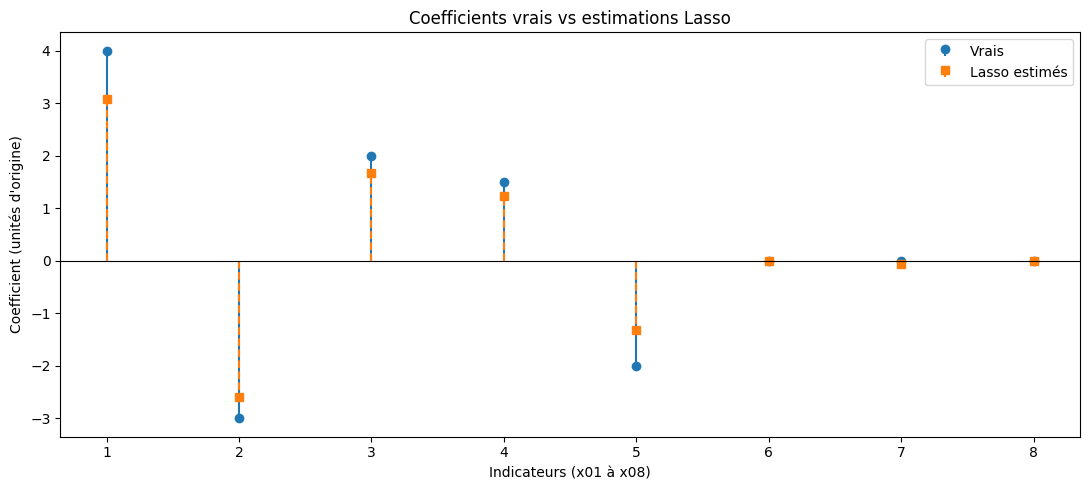

In [ ]:
beta_vrai = np.zeros(len(vars_mk)); beta_vrai[:5] = [4., -3., 2., 1.5, -2.]
fig, ax = plt.subplots(figsize=(11, 5))
ax.stem(range(1, 9), beta_vrai[:8], linefmt="C0-", markerfmt="C0o", basefmt=" ", label="Vrais")
ax.stem(range(1, 9), coef_lasso[:8], linefmt="C1--", markerfmt="C1s", basefmt=" ", label="Lasso estimés")
ax.axhline(0, color="k", linewidth=0.8)
ax.set_xlabel("Indicateurs (x01 à x08)"); ax.set_ylabel("Coefficient (unités d'origine)")
ax.set_title("Coefficients vrais vs estimations Lasso")
ax.legend()
montrer(fig, "marketing_lasso")

In [ ]:
pool = pd.read_csv(chemin("bayes_pool.csv"))
test_bayes = pd.read_csv(chemin("bayes_test.csv"))
vars_bayes = [c for c in pool.columns if c != "y"]
print("Pool :", pool.shape, "| Test :", test_bayes.shape)

def bayesian_interval(modele, X, niveau=0.95):
    Xt = X
    for _, etape in modele.steps[:-1]:
        Xt = etape.transform(Xt)
    mu, std = modele.named_steps["model"].predict(Xt, return_std=True)
    z = norm.ppf(0.5 + niveau / 2)
    return mu, mu - z * std, mu + z * std

def interval_metrics(y_vrai, borne_inf, borne_sup):
    y = np.asarray(y_vrai)
    return {"Couverture": float(np.mean((y >= borne_inf) & (y <= borne_sup))),
            "Largeur moyenne": float(np.mean(borne_sup - borne_inf))}

Xb_tr = pool[vars_bayes].iloc[:100]; yb_tr = pool["y"].iloc[:100]
ols_b = Pipeline([("sc", StandardScaler()), ("model", LinearRegression())]).fit(Xb_tr, yb_tr)
bay_b = Pipeline([("sc", StandardScaler()), ("model", BayesianRidge())]).fit(Xb_tr, yb_tr)
mu, lo, hi = bayesian_interval(bay_b, test_bayes[vars_bayes])
print("OLS   - première réplication :", {k: round(v, 3) for k, v in regression_metrics(test_bayes['y'], ols_b.predict(test_bayes[vars_bayes])).items()})
print("Bayes - première réplication :", {k: round(v, 3) for k, v in regression_metrics(test_bayes['y'], bay_b.predict(test_bayes[vars_bayes])).items()})
print("Intervalle bayésien :", {k: round(v, 3) for k, v in interval_metrics(test_bayes['y'], lo, hi).items()})

Pool : (200, 9) | Test : (1000, 9)
OLS   - première réplication : {'MAE': 3.187, 'MSE': 15.851, 'RMSE': 3.981, 'R2': 0.774}
Bayes - première réplication : {'MAE': 3.217, 'MSE': 16.088, 'RMSE': 4.011, 'R2': 0.771}
Intervalle bayésien : {'Couverture': 0.975, 'Largeur moyenne': 17.788}


In [ ]:
tailles_bayes = [10, 20, 50, 100, 200]
lignes_bayes = []
for r in range(REPETITIONS):
    pool_r = make_bayes_data(200, 0.2, 4., SEED + 100 + r)
    test_r = make_bayes_data(1000, 0.2, 4., SEED + 200 + r)
    for n in tailles_bayes:
        sous = pool_r.iloc[:n]
        ols = Pipeline([("sc", StandardScaler()), ("model", LinearRegression())]).fit(sous[vars_bayes], sous["y"])
        bay = Pipeline([("sc", StandardScaler()), ("model", BayesianRidge())]).fit(sous[vars_bayes], sous["y"])
        rmse_ols = np.sqrt(mean_squared_error(test_r["y"], ols.predict(test_r[vars_bayes])))
        rmse_bay = np.sqrt(mean_squared_error(test_r["y"], bay.predict(test_r[vars_bayes])))
        mu, lo, hi = bayesian_interval(bay, test_r[vars_bayes])
        im = interval_metrics(test_r["y"], lo, hi)
        lignes_bayes.append({"Taille": n, "Réplication": r, "RMSE OLS": rmse_ols,
                             "RMSE bayésienne": rmse_bay, **im})
df_bayes = pd.DataFrame(lignes_bayes)
synthese_bayes = df_bayes.groupby("Taille").agg(
    **{"RMSE OLS": ("RMSE OLS", "mean"),
       "RMSE bayésienne": ("RMSE bayésienne", "mean"),
       "Couverture": ("Couverture", "mean"),
       "Largeur": ("Largeur moyenne", "mean")})
display(synthese_bayes.round(3))

,RMSE OLS,RMSE bayésienne,Couverture,Largeur
Taille,,,,
10,13.534,6.322,0.874,21.283
20,5.497,5.344,0.913,18.120
50,4.323,4.327,0.929,15.847
100,4.089,4.096,0.948,15.933
200,4.000,4.001,0.956,15.800


comparer les degrés de 1 à 6

Nous allons utiliser une validation croisée à 5 plis (5-fold cross-validation) pour choisir le meilleur degré sans utiliser les données de test.

Degré 1 : modèle linéaire.

Degré 2 : modèle quadratique.

Degrés 3 à 6 : modèles polynomiaux plus complexes.

Pour chaque degré, nous calculons le RMSE moyen et sa dispersion sur les 5 plis. Plus le RMSE est faible, meilleures sont les prédictions.




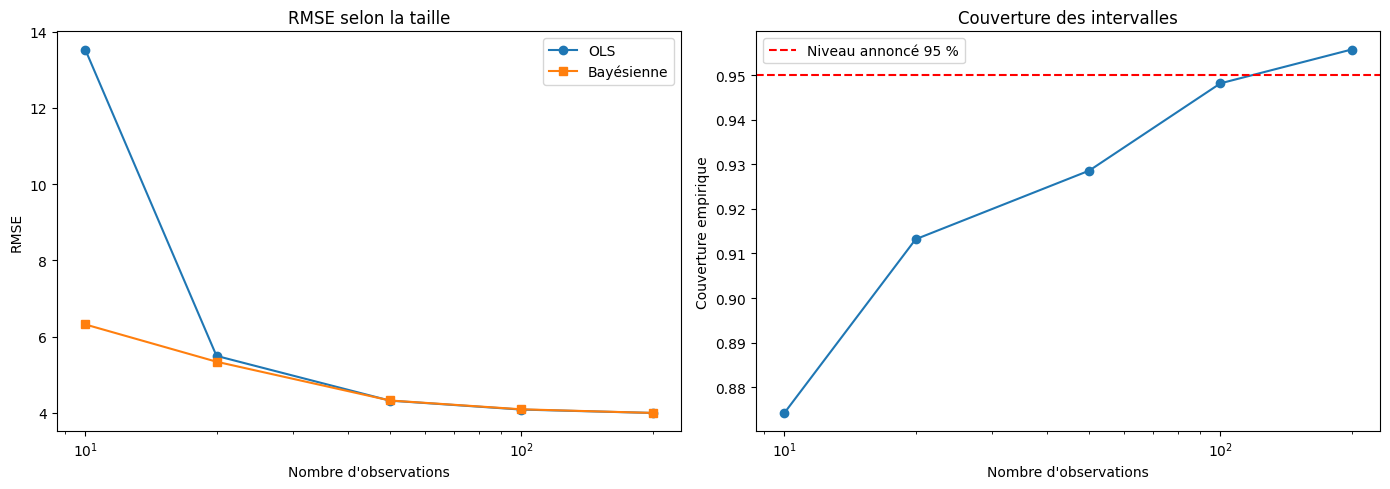

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(synthese_bayes.index, synthese_bayes["RMSE OLS"], marker="o", label="OLS")
axes[0].plot(synthese_bayes.index, synthese_bayes["RMSE bayésienne"], marker="s", label="Bayésienne")
axes[0].set_xscale("log"); axes[0].set_xlabel("Nombre d'observations")
axes[0].set_ylabel("RMSE"); axes[0].set_title("RMSE selon la taille"); axes[0].legend()

axes[1].plot(synthese_bayes.index, synthese_bayes["Couverture"], marker="o")
axes[1].axhline(0.95, color="red", linestyle="--", label="Niveau annoncé 95 %")
axes[1].set_xscale("log"); axes[1].set_xlabel("Nombre d'observations")
axes[1].set_ylabel("Couverture empirique"); axes[1].set_title("Couverture des intervalles")
axes[1].legend()
montrer(fig, "bayes_courbes")

Q 26 : La validation croisée montre que le degré 1 est insuffisant pour représenter la relation non linéaire entre la température et la consommation énergétique. Le degré 5 obtient le RMSE moyen le plus faible (39,665 MWh), mais son amélioration par rapport au degré 2 est très faible. Le degré 2 constitue donc un choix plus simple, avec des performances comparables. La relation simulée étant quadratique, le degré 2 est également cohérent avec le mécanisme utilisé pour générer les données.

Comparer le modèle linéaire et le modèle polynomial

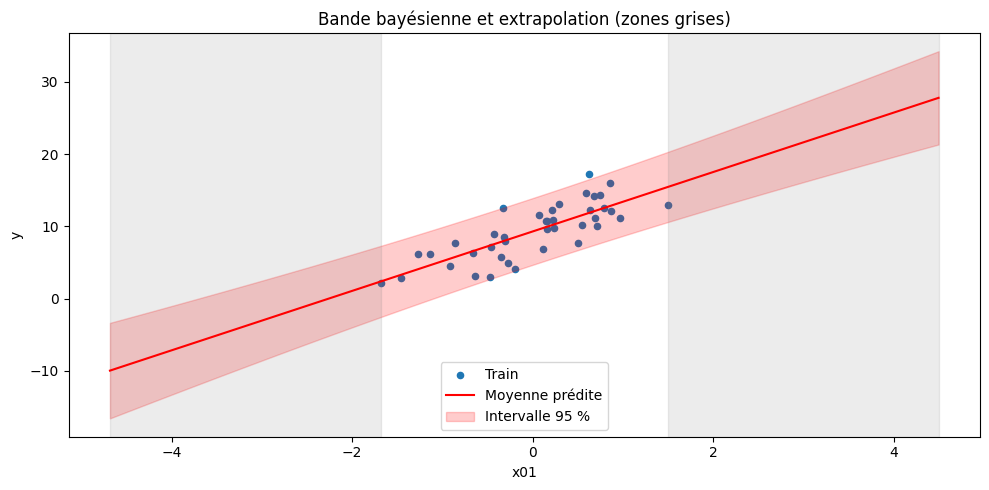

In [ ]:
d_une = make_linear_data(40, 1, 1, 3.0, 0.0, SEED)
m_une = Pipeline([("sc", StandardScaler()), ("model", BayesianRidge())]).fit(d_une[["x01"]], d_une["y"])
x_min, x_max = d_une["x01"].min(), d_une["x01"].max()
grille = pd.DataFrame({"x01": np.linspace(x_min - 3, x_max + 3, 300)})
mu, lo, hi = bayesian_interval(m_une, grille[["x01"]])
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(d_une["x01"], d_une["y"], s=20, label="Train")
ax.plot(grille["x01"], mu, color="red", label="Moyenne prédite")
ax.fill_between(grille["x01"], lo, hi, color="red", alpha=0.2, label="Intervalle 95 %")
ax.axvspan(x_min - 3, x_min, color="grey", alpha=0.15)
ax.axvspan(x_max, x_max + 3, color="grey", alpha=0.15)
ax.set_xlabel("x01"); ax.set_ylabel("y")
ax.set_title("Bande bayésienne et extrapolation (zones grises)"); ax.legend()
montrer(fig, "bayes_bande")

Q 28 : Le modèle polynomial de degré 2 est nettement meilleur que le modèle linéaire. Sur les données de test, son MAE passe de 73,016 à 33,475 MWh et son RMSE de 85,714 à 41,904 MWh. Son coefficient de détermination R² atteint 0,796 contre 0,148 pour le modèle linéaire. Cette amélioration est importante et montre que le modèle quadratique représente mieux la relation non linéaire entre la température et la consommation énergétique.

In [ ]:
def fit_ols(X, y):
    return Pipeline([("sc", StandardScaler()), ("model", LinearRegression())]).fit(X, y)

def fit_ridge(X, y):
    return Pipeline([("sc", StandardScaler()),
                     ("model", RidgeCV(alphas=np.logspace(-2, 3, 13)))]).fit(X, y)

def run_sweep(tailles, bruits, correlations, rep, n_test=1000, graine=SEED):
    lignes = []
    for taille, bruit, rho in [(a, b, c) for a in tailles for b in bruits for c in correlations]:
        differences = []
        for r in range(rep):
            train = make_linear_data(taille, 15, 5, bruit, rho, graine + 1000 * r + taille)
            test = make_linear_data(n_test, 15, 5, bruit, rho, graine + 5000 * r + taille)
            f = ["x{:02d}".format(j + 1) for j in range(15)]
            o = fit_ols(train[f], train["y"]); ri = fit_ridge(train[f], train["y"])
            rmse_o = np.sqrt(mean_squared_error(test["y"], o.predict(test[f])))
            rmse_r = np.sqrt(mean_squared_error(test["y"], ri.predict(test[f])))
            differences.append(rmse_o - rmse_r)
        d = np.array(differences)
        lignes.append({"Taille": taille, "Bruit": bruit, "Corrélation": rho,
                       "Gain moyen": d.mean(), "Écart-type": d.std(ddof=1),
                       "Erreur MC": d.std(ddof=1) / np.sqrt(rep)})
    return pd.DataFrame(lignes)

sweep_5 = run_sweep([40, 120], [1, 4], [0, 0.95], rep=5)
display(sweep_5.round(3))

,Taille,Bruit,Corrélation,Gain moyen,Écart-type,Erreur MC
0,40,1,0.00,-0.002,0.044,0.020
1,40,1,0.95,0.069,0.103,0.046
2,40,4,0.00,0.273,0.369,0.165
3,40,4,0.95,1.044,0.353,0.158
4,120,1,0.00,0.001,0.002,0.001
5,120,1,0.95,0.007,0.006,0.003
6,120,4,0.00,0.034,0.033,0.015
7,120,4,0.95,0.148,0.058,0.026


Modèle linéaire : Il est inadapté, car il représente la relation entre la température et la consommation énergétique par une droite, alors que les données présentent une relation non linéaire.

Modèle polynomial de degré 2 : Il représente la forme en U des données. La consommation énergétique est élevée lorsque la température est très basse ou très élevée, et plus faible pour des températures intermédiaires. Ce modèle s'ajuste mieux aux observations d'entraînement et de test, ce qui est cohérent avec ses meilleures performances sur les données de test.

Question 27 : pourquoi centrer la température ? Centrer ou standardiser la température avant de calculer ses puissances permet de limiter les problèmes numériques, notamment lorsque le degré du polynôme est élevé. En effet, les puissances successives peuvent devenir très grandes et rendre l'estimation des coefficients instable. Un degré élevé augmente également le risque de surapprentissage et peut produire des oscillations inutiles.

Q29 : Pourquoi choisir le modèle le plus simple lorsque deux degrés ont des scores de validation similaires ? Pourquoi la dispersion entre les plis n'est-elle pas automatiquement un intervalle de confiance ? Lorsque deux degrés ont des scores de validation similaires, on privilégie généralement le modèle le plus simple, car il est plus facile à interpréter et présente moins de risques de surapprentissage. La dispersion entre les plis mesure la variabilité des performances selon les sous-échantillons utilisés, mais elle ne constitue pas automatiquement un intervalle de confiance, car les scores des plis ne sont pas nécessairement indépendants.

In [ ]:
class TestAtelierRegression(unittest.TestCase):

    def test_metriques_egales_a_la_reference(self):
        cas = [([1, 2, 3], [1, 2, 5]), ([0., 1., 2.], [0.1, 1.1, 1.9])]
        for y, p in cas:
            np.testing.assert_allclose(list(calculer_metriques(y, p).values()),
                                       list(regression_metrics(y, p).values()), rtol=1e-12)

    def test_metriques_cible_constante_renvoie_nan(self):
        self.assertTrue(np.isnan(calculer_metriques([2, 2, 2], [2, 2, 1])["R2"]))

    def test_metriques_tailles_incompatibles_leve_exception(self):
        with self.assertRaises(ValueError):
            calculer_metriques([1, 2, 3], [1, 2])

    def test_metriques_refuse_les_valeurs_non_finies(self):
        with self.assertRaises(ValueError):
            calculer_metriques([1, 2, 3], [1, np.inf, 3])

    def test_make_curve_forme_et_colonnes(self):
        d = make_curve(n=50, kind="energie", noise=10, seed=1)
        self.assertEqual(d.shape, (50, 2))
        self.assertListEqual(list(d.columns), ["temperature_c", "energie_mwh"])

    def test_load_numeric_csv_supprime_doublons_et_infinis(self):
        propre, avant, apres = load_numeric_csv(chemin("vehicules_co2_brut.csv"), "co2_g_km", entrees)
        self.assertEqual(apres["Doublons exacts"], 0)
        self.assertEqual(apres["Valeurs infinies"], 0)
        self.assertEqual(apres["Cibles manquantes"], 0)
        self.assertLess(apres["Nombre de lignes"], avant["Nombre de lignes"])

    def test_separation_sans_fuite(self):
        self.assertEqual(len(set(X_train.index) & set(X_test.index)), 0)


resultat_tests = unittest.TextTestRunner(verbosity=2).run(
    unittest.TestLoader().loadTestsFromTestCase(TestAtelierRegression))
print("Tests réussis :", resultat_tests.wasSuccessful())

test_load_numeric_csv_supprime_doublons_et_infinis (__main__.TestAtelierRegression.test_load_numeric_csv_supprime_doublons_et_infinis) ... ok
test_make_curve_forme_et_colonnes (__main__.TestAtelierRegression.test_make_curve_forme_et_colonnes) ... ok
test_metriques_cible_constante_renvoie_nan (__main__.TestAtelierRegression.test_metriques_cible_constante_renvoie_nan) ... ok
test_metriques_egales_a_la_reference (__main__.TestAtelierRegression.test_metriques_egales_a_la_reference) ... ok
test_metriques_refuse_les_valeurs_non_finies (__main__.TestAtelierRegression.test_metriques_refuse_les_valeurs_non_finies) ... ok
test_metriques_tailles_incompatibles_leve_exception (__main__.TestAtelierRegression.test_metriques_tailles_incompatibles_leve_exception) ... ok
test_separation_sans_fuite (__main__.TestAtelierRegression.test_separation_sans_fuite) ... ok

----------------------------------------------------------------------
Ran 7 tests in 0.042s

OK


Tests réussis : True


Modèle linéaire : Il est inadapté car il trace une ligne droite, alors que la relation entre la température et la consommation énergétique n'est pas linéaire.
Modèle polynomial : Il capture parfaitement la forme en « U » des données (la consommation d'énergie est forte quand il fait très froid ou très chaud, et minimale autour de 10-15 °C), s'ajustant très bien aux points d'entraînement et de test.

Q30. L’extrapolation correspond aux prédictions réalisées en dehors de l’intervalle des températures observées dans les données d’entraînement. Sur le graphique, elle concerne les températures inférieures au minimum observé et supérieures au maximum observé, jusqu’à −15 °C et 45 °C. Le modèle polynomial de degré 2 représente mieux la relation en forme de U que le modèle linéaire. Cependant, même si la courbe paraît régulière, les prédictions en extrapolation restent moins fiables, car elles sont réalisées en dehors de la plage des données utilisées pour entraîner le modèle.

Activité 7 — Repérer le surajustement

L’objectif est de comparer un modèle entraîné sur seulement 30 ventes avec des données indépendantes contenant 1 000 ventes pour diagnostiquer sa capacité de généralisation.

In [ ]:
base = df_co2.copy()
memoire = {
    "CO₂ float64 (Mo)": base.memory_usage(deep=True).sum() / 1e6,
    "CO₂ float32 (Mo)": base.astype({c: "float32" for c in base.select_dtypes("float")}).memory_usage(deep=True).sum() / 1e6,
}
serie_texte = pd.Series(["rouge", "bleu", "vert"] * 1000)
memoire["object (octets)"] = serie_texte.memory_usage(deep=True)
memoire["category (octets)"] = serie_texte.astype("category").memory_usage(deep=True)
display(pd.Series(memoire))
ecart = np.abs(df_co2["co2_g_km"].astype("float32").astype("float64") - df_co2["co2_g_km"]).max()
print("Écart numérique max dû à la conversion float32 :", ecart)

,0
CO₂ float64 (Mo),0.032512
CO₂ float32 (Mo),0.026128
object (octets),160132.000000
category (octets),3400.000000


Écart numérique max dû à la conversion float32 : 1.5046650446493004e-05


In [ ]:
CSV_EXTERNE = chemin("vehicules_co2_brut.csv")
CIBLE_EXTERNE = "co2_g_km"
VARIABLES_EXTERNES = entrees
SEP, DECIMAL = ",", "."
donnees_externes, audit_ext_avant, audit_ext_apres = load_numeric_csv(
    CSV_EXTERNE, CIBLE_EXTERNE, VARIABLES_EXTERNES,
    drop_duplicates=True, sep=SEP, decimal=DECIMAL)
print("CSV externe prêt :", donnees_externes.shape,
      "| cible :", CIBLE_EXTERNE, "| variables :", VARIABLES_EXTERNES)

CSV externe prêt : (399, 4) | cible : co2_g_km | variables : ['cylindree_l', 'cylindres', 'consommation_l_100km']


In [ ]:
synthese_df = pd.DataFrame(synthese)
synthese_df.to_csv(SORTIES / "tableau_suivi.csv", index=False)
tableau_co2.to_csv(SORTIES / "resultats_co2.csv", index=False)
df_cv_e.to_csv(SORTIES / "validation_energie.csv", index=False)
df_7.to_csv(SORTIES / "surajustement_immobilier.csv", index=False)
tableau_ridge.to_csv(SORTIES / "ols_vs_ridge.csv", index=False)
tableau_mk.to_csv(SORTIES / "ols_ridge_lasso.csv", index=False)
tableau_selection.to_csv(SORTIES / "selection_lasso.csv", index=False)
synthese_bayes.to_csv(SORTIES / "bayes_couverture.csv")
sweep_5.to_csv(SORTIES / "sweep_5_replications.csv", index=False)

manifeste = {
    "graine": SEED,
    "mode_rapide": MODE_RAPIDE,
    "replications": REPETITIONS,
    "versions": versions,
    "unites": {"co2": "g/km", "energie": "MWh", "immobilier": "k€", "autres": "unités simulées"},
    "donnees": {},
}
for nom in ["vehicules_co2_brut.csv", "energie_temperature.csv",
            "immobilier_train.csv", "immobilier_diagnostic.csv",
            "ridge_train.csv", "ridge_test.csv", "marketing_train.csv",
            "marketing_test.csv", "bayes_pool.csv", "bayes_test.csv"]:
    p = chemin(nom)
    if p.exists():
        manifeste["donnees"][nom] = hashlib.sha256(p.read_bytes()).hexdigest()
with open(SORTIES / "manifeste.json", "w", encoding="utf-8") as f:
    json.dump(manifeste, f, indent=2, ensure_ascii=False)
print("Fichiers exportés dans :", SORTIES.resolve())
print("Manifeste :", json.dumps({"graine": SEED, "mode_rapide": MODE_RAPIDE,
                                 "nb_donnees_hachees": len(manifeste["donnees"])}, ensure_ascii=False))

Fichiers exportés dans : /content/sorties_regression
Manifeste : {"graine": 42, "mode_rapide": true, "nb_donnees_hachees": 10}


Pour chaque degré, nous allons entraîner le modèle sur les 30 ventes, puis calculer le RMSE sur les données d’entraînement et sur les 1 000 ventes indépendantes.

,Taille train,Degré,RMSE train,RMSE diagnostic
0,30,1,23.109,26.918
1,30,2,22.030,25.320
2,30,3,20.916,28.087
3,30,4,20.158,26.693
4,30,5,20.033,27.266
5,30,6,19.986,26.917
6,30,7,19.060,44.780
7,30,8,17.627,51.399
8,30,9,15.808,142.427
9,30,10,15.802,128.828


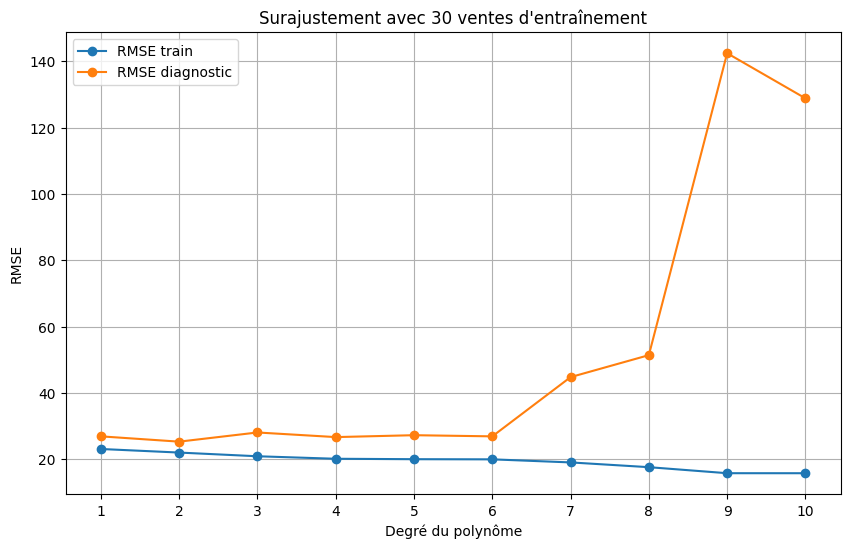

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X_train = X_30
y_train = y_30

X_diag = X_diag
y_diag = y_diag

resultats_30 = []

for degre in range(1, 11):
    modele = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=degre, include_bias=False),
        LinearRegression()
    )

    modele.fit(X_train, y_train)

    pred_train = modele.predict(X_train)
    pred_diag = modele.predict(X_diag)

    resultats_30.append({
        "Taille train": 30,
        "Degré": degre,
        "RMSE train": np.sqrt(mean_squared_error(y_train, pred_train)),
        "RMSE diagnostic": np.sqrt(mean_squared_error(y_diag, pred_diag))
    })

tableau_30 = pd.DataFrame(resultats_30)
display(tableau_30.round(3))

plt.figure(figsize=(10, 6))
plt.plot(tableau_30["Degré"], tableau_30["RMSE train"], marker="o", label="RMSE train")
plt.plot(tableau_30["Degré"], tableau_30["RMSE diagnostic"], marker="o", label="RMSE diagnostic")
plt.xlabel("Degré du polynôme")
plt.ylabel("RMSE")
plt.title("Surajustement avec 30 ventes d'entraînement")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)
plt.show()

Interprétation du graphique :

Erreur d’entraînement : Elle diminue généralement lorsque le degré du polynôme augmente, car le modèle devient plus flexible et s’adapte davantage aux données d’entraînement.

Erreur de diagnostic : Elle est minimale pour un degré faible, autour de 2 ou 3, puis augmente fortement à partir des degrés élevés, notamment 9 et 10.

Conclusion : Ce comportement illustre le surajustement/overfitting. Le modèle devient trop complexe et apprend les particularités du petit échantillon plutôt que la relation générale. Il obtient alors une faible erreur d’entraînement, mais prédit moins bien les nouvelles ventes.

Nous allons maintenant visualiser les 30 ventes et les deux courbes pour observer concrètement leur différence.

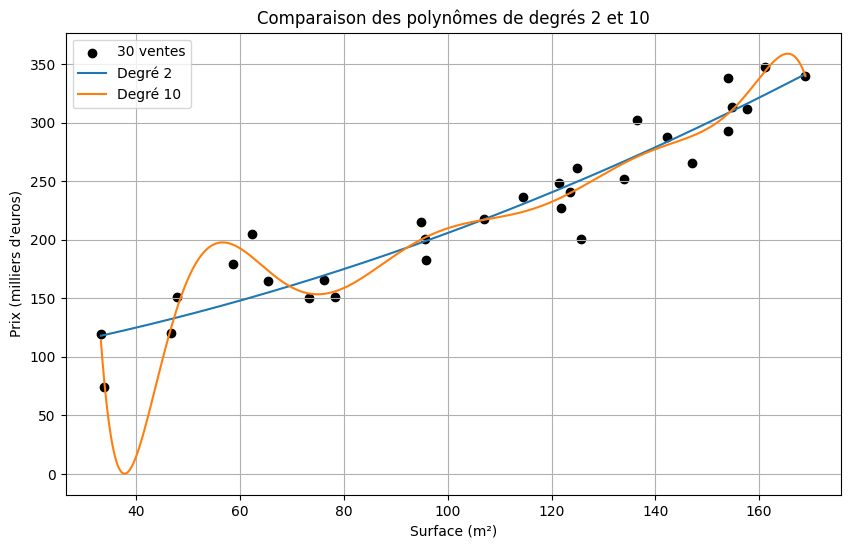

In [ ]:
grille = pd.DataFrame({
    "surface_m2": np.linspace(
        df_train_30["surface_m2"].min(),
        df_train_30["surface_m2"].max(),
        500
    )
})

plt.figure(figsize=(10, 6))
plt.scatter(
    df_train_30["surface_m2"],
    df_train_30["prix_k_eur"],
    label="30 ventes",
    color="black"
)

for degre in [2, 10]:
    modele = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=degre, include_bias=False),
        LinearRegression()
    )
    modele.fit(X_train, y_train)

    plt.plot(
        grille["surface_m2"],
        modele.predict(grille),
        label=f"Degré {degre}"
    )

plt.xlabel("Surface (m²)")
plt.ylabel("Prix (milliers d'euros)")
plt.title("Comparaison des polynômes de degrés 2 et 10")
plt.legend()
plt.grid(True)
plt.show()

Degré 2 : La courbe représente la tendance générale des prix en fonction de la surface de manière relativement régulière, sans variations excessives.

Degré 10 : La courbe présente des oscillations importantes, caractéristiques du surajustement. Elle s’adapte excessivement aux 30 observations d’entraînement et peut produire des prédictions irréalistes, notamment des prix négatifs pour certaines surfaces. Elle risque donc de mal généraliser à de nouvelles ventes.

Conclusion : Un modèle plus complexe ne garantit pas de meilleures prédictions. Il faut trouver un équilibre entre l’ajustement aux données d’entraînement et la capacité de généralisation.

In [ ]:
ventes_100 = make_curve(100, "immobilier", 25, SEED + 20)

X_train_100 = ventes_100[["surface_m2"]]
y_train_100 = ventes_100["prix_k_eur"]

resultats_100 = []

for degre in range(1, 11):
    modele = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=degre, include_bias=False),
        LinearRegression()
    )

    modele.fit(X_train_100, y_train_100)

    pred_train = modele.predict(X_train_100)
    pred_diag = modele.predict(X_diag)

    resultats_100.append({
        "Taille train": 100,
        "Degré": degre,
        "RMSE train": np.sqrt(mean_squared_error(y_train_100, pred_train)),
        "RMSE diagnostic": np.sqrt(mean_squared_error(y_diag, pred_diag))
    })

tableau_100 = pd.DataFrame(resultats_100)
display(tableau_100.round(3))

,Taille train,Degré,RMSE train,RMSE diagnostic
0,100,1,23.954,26.706
1,100,2,22.324,24.800
2,100,3,22.238,24.750
3,100,4,21.913,25.778
4,100,5,21.635,25.869
5,100,6,21.624,25.934
6,100,7,21.622,25.952
7,100,8,21.582,26.047
8,100,9,21.572,26.753
9,100,10,21.558,28.424


Degré 1 : le RMSE de diagnostic est de 32,194, ce qui montre que la droite représente moins bien la relation non linéaire.

Degré 3 : il obtient le RMSE de diagnostic le plus faible, soit 24,750.

Degrés 4 à 10 : l’erreur d’entraînement continue globalement à diminuer, mais l’erreur de diagnostic augmente. Au degré 10, elle atteint 28,424. Cela illustre le surajustement : le modèle s’adapte de plus en plus aux données d’entraînement, sans améliorer ses prédictions sur les nouvelles ventes.

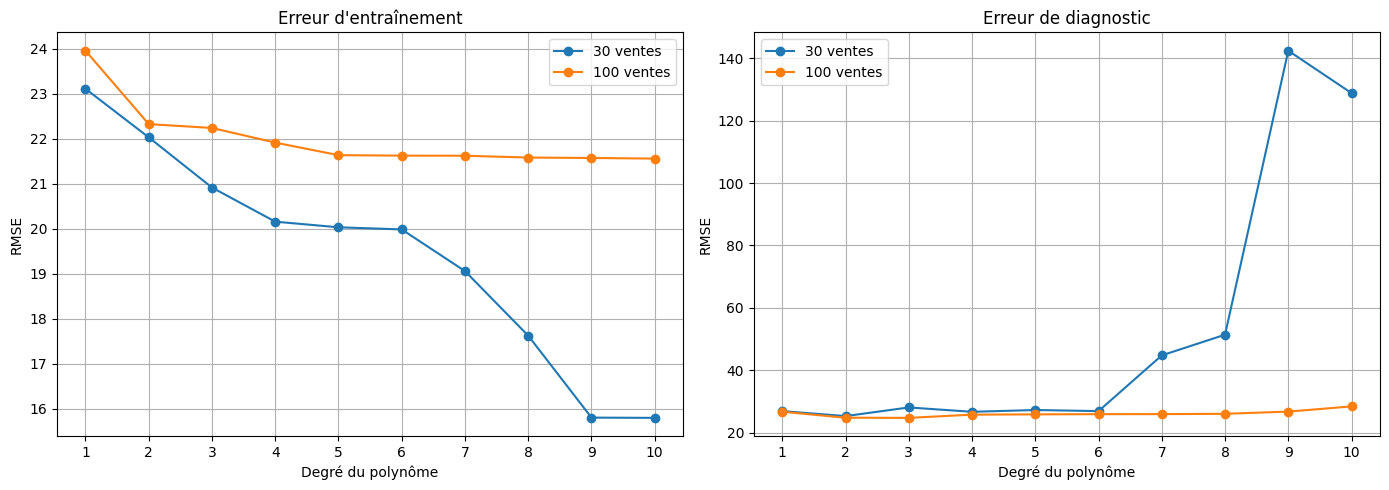

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for taille, tableau in [(30, tableau_30), (100, tableau_100)]:
    axes[0].plot(tableau["Degré"], tableau["RMSE train"], marker="o", label=f"{taille} ventes")
    axes[1].plot(tableau["Degré"], tableau["RMSE diagnostic"], marker="o", label=f"{taille} ventes")

axes[0].set_title("Erreur d'entraînement")
axes[1].set_title("Erreur de diagnostic")

for ax in axes:
    ax.set_xlabel("Degré du polynôme")
    ax.set_ylabel("RMSE")
    ax.set_xticks(range(1, 11))
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

Erreur d’entraînement : L’erreur diminue généralement lorsque le degré du polynôme augmente, car le modèle devient plus flexible et s’adapte davantage aux données d’entraînement.

Erreur de diagnostic :

Avec 30 ventes, l’erreur augmente fortement aux degrés élevés. Au degré 10, le RMSE d’entraînement est de 15,802, tandis que le RMSE de diagnostic atteint 128,828. Cet écart important illustre le surajustement.
Avec 100 ventes, le RMSE d’entraînement au degré 10 est de 21,558 et le RMSE de diagnostic de 28,424. L’écart est nettement plus faible qu’avec 30 ventes.
Conclusion : Augmenter la taille de l’échantillon peut réduire le surajustement et améliorer la généralisation. Cependant, cela ne supprime pas systématiquement le surajustement, comme le montre l’augmentation de l’erreur de diagnostic aux degrés élevés avec 100 ventes.

Q31. Lorsque le degré augmente, l’erreur d’entraînement diminue généralement, car le modèle devient plus complexe. Sur les nouvelles ventes, l’erreur diminue d’abord, puis peut augmenter à cause du surajustement.

Q32. Avec 100 ventes, le degré 10 présente un RMSE d’entraînement de 21,558, mais un RMSE de diagnostic de 28,424. L’erreur d’entraînement est donc plus faible que l’erreur sur les nouvelles données, ce qui illustre une dégradation de la généralisation.

Q33. Un polynôme de degré élevé peut devenir instable près des limites de la plage observée, car ses puissances élevées peuvent entraîner de fortes variations. Le graphique du degré 10 illustre ce phénomène par des oscillations et des prédictions parfois irréalistes.

Q34. Le passage de 30 à 100 observations peut réduire l’écart entre l’entraînement et le diagnostic en fournissant davantage d’informations au modèle. Cependant, cette conclusion doit être vérifiée en comparant les tableaux et les graphiques. Une seule simulation ne suffit pas pour établir une règle générale.

Q35. Le jeu de diagnostic de 1 000 ventes permet d’illustrer le surajustement, mais son utilisation répétée pour choisir le degré revient à exploiter indirectement les données d’évaluation. Pour sélectionner un modèle correctement, il faut séparer les données en trois ensembles : un jeu d’entraînement pour ajuster les modèles, une validation croisée sur l’entraînement pour choisir le degré, puis un jeu de test final indépendant, utilisé une seule fois pour évaluer les performances du modèle retenu.

Activité 8 : Stabiliser un modèle avec Ridge. L’objectif est de comparer deux modèles :

OLS (régression linéaire classique) : minimise l’erreur de prédiction sans pénalisation.

Ridge : minimise l’erreur de prédiction en ajoutant une pénalisation sur les coefficients, ce qui peut les stabiliser lorsque les variables sont très corrélées.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(42)

def generer_donnees_ridge(n, correlation=0.98, seed=42):
    rng = np.random.default_rng(seed)
    facteur = rng.normal(size=(n, 1))
    X = np.sqrt(correlation) * facteur + np.sqrt(1 - correlation) * rng.normal(size=(n, 15))
    coefficients = np.array([3, -2, 1.5, 2, -1] + [0] * 10)
    y = X @ coefficients + rng.normal(0, 3, n)
    colonnes = [f"X{i}" for i in range(1, 16)]
    return pd.DataFrame(X, columns=colonnes), pd.Series(y, name="y")

X_train_ridge, y_train_ridge = generer_donnees_ridge(40, seed=42)
X_test_ridge, y_test_ridge = generer_donnees_ridge(1000, seed=43)

print("Entraînement :", X_train_ridge.shape, y_train_ridge.shape)
print("Test :", X_test_ridge.shape, y_test_ridge.shape)

display(X_train_ridge.head())

Entraînement : (40, 15) (40,)
Test : (1000, 15) (1000,)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15
0,0.406767,0.378468,0.207537,0.334487,0.318156,0.332582,0.424893,0.333276,0.397667,0.311212,0.342542,0.390932,0.095582,0.256446,0.235134
1,-1.119883,-1.068443,-0.818115,-1.151979,-0.892597,-1.267525,-1.076892,-1.006515,-0.946627,-0.928949,-0.917335,-1.078849,-1.094918,-0.908196,-1.056586
2,0.562499,0.582638,0.612879,0.813218,0.763051,0.840558,0.682486,0.765330,0.831381,0.699161,0.807507,0.649298,0.691565,0.688923,0.573792
3,0.999980,0.864728,0.932878,0.999099,0.994261,1.025211,0.917184,0.871248,0.919838,0.692486,0.726459,0.744054,0.790080,0.987648,0.803057
4,-1.984907,-1.747688,-1.981810,-1.827126,-2.063460,-1.960480,-2.065780,-1.979373,-1.812589,-2.175706,-1.869990,-1.897805,-2.015452,-2.135930,-1.921226


Comparer OLS et Ridge

Ridge ajoute une pénalisation sur les coefficients. Comme les variables sont très corrélées et qu’il y a peu d’observations, cette pénalisation peut améliorer la généralisation.

Pour commencer, on fixe arbitrairement α=1. Nous choisirons ensuite le meilleur alpha par validation croisée.

In [ ]:

from sklearn.metrics import mean_squared_error

ols = LinearRegression()
ridge = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1)
)

ols.fit(X_train_ridge, y_train_ridge)
ridge.fit(X_train_ridge, y_train_ridge)

pred_ols = ols.predict(X_test_ridge)
pred_ridge = ridge.predict(X_test_ridge)

resultats = pd.DataFrame({
    "Modèle": ["OLS", "Ridge (alpha=1)"],
    "RMSE test": [
        np.sqrt(mean_squared_error(y_test_ridge, pred_ols)),
        np.sqrt(mean_squared_error(y_test_ridge, pred_ridge))
    ]
})

display(resultats.round(3))

,Modèle,RMSE test
0,OLS,4.184
1,Ridge (alpha=1),3.143


Choisir le meilleur alpha par validation croisée

Nous allons tester plusieurs valeurs d’alpha en utilisant uniquement les données d’entraînement. Le jeu de test restera indépendant et ne servira pas à choisir le modèle.

In [ ]:
from sklearn.model_selection import GridSearchCV, KFold

pipeline_ridge = make_pipeline(
    StandardScaler(),
    Ridge()
)

grille = {
    "ridge__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

recherche = GridSearchCV(
    pipeline_ridge,
    grille,
    scoring="neg_root_mean_squared_error",
    cv=cv
)

recherche.fit(X_train_ridge, y_train_ridge)

print("Meilleur alpha :", recherche.best_params_["ridge__alpha"])
print("RMSE moyen en validation :", -recherche.best_score_)

meilleur_ridge = recherche.best_estimator_
pred_ridge_cv = meilleur_ridge.predict(X_test_ridge)

print("RMSE test OLS :", round(np.sqrt(mean_squared_error(y_test_ridge, pred_ols)), 3))
print("RMSE test Ridge optimisé :", round(np.sqrt(mean_squared_error(y_test_ridge, pred_ridge_cv)), 3))

Meilleur alpha : 10
RMSE moyen en validation : 3.5497189206591635
RMSE test OLS : 4.184
RMSE test Ridge optimisé : 3.091


La validation croisée sélectionne α=10. Sur le jeu de test, Ridge optimisé obtient un RMSE de 3,091, contre 4,184 pour OLS.

Le gain relatif de RMSE est :

(4,184−3,091) / 4,184 × 100≈26,1%

Ridge optimisé réduit donc le RMSE de test d’environ 26,1 % par rapport à OLS sur cette simulation.

Maintenant, nous allons légèrement modifier les valeurs de y plusieurs fois, puis comparer les coefficients obtenus par OLS et Ridge. L’idée est de vérifier si de petites perturbations des données entraînent de grands changements dans les coefficients.

,Variable,Dispersion OLS,Dispersion Ridge
0,X1,0.725,0.051
1,X2,1.039,0.052
2,X3,0.712,0.060
3,X4,0.697,0.057
4,X5,0.787,0.061
5,X6,0.515,0.059
6,X7,0.850,0.057
7,X8,0.646,0.057
8,X9,0.544,0.056
9,X10,0.793,0.062


<Axes: title={'center': 'Dispersion des coefficients après perturbation'}, xlabel='Variable'>

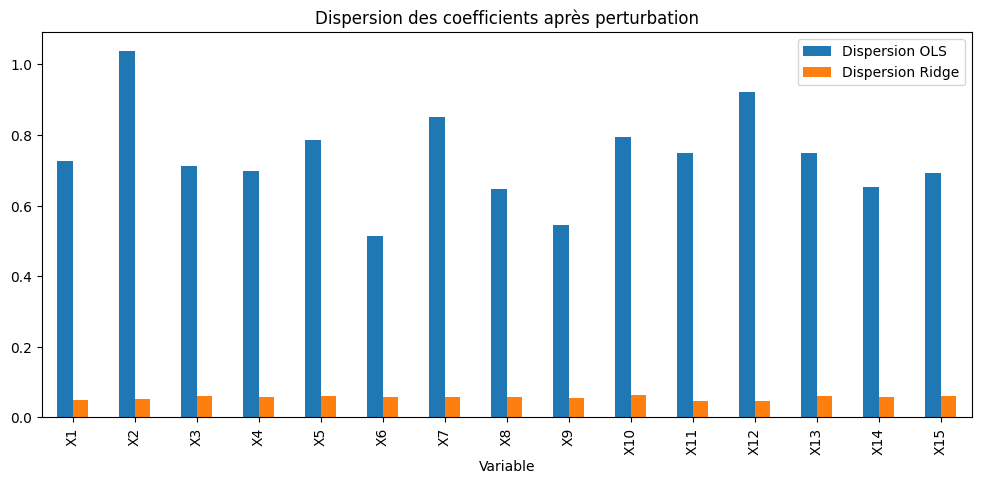

In [ ]:
n_repetitions = 100
rng = np.random.default_rng(123)

coef_ols = []
coef_ridge = []

for _ in range(n_repetitions):
    y_perturbe = y_train_ridge + rng.normal(0, 0.5, len(y_train_ridge))

    modele_ols = LinearRegression()
    modele_ols.fit(X_train_ridge, y_perturbe)
    coef_ols.append(modele_ols.coef_)

    modele_ridge = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10)
    )
    modele_ridge.fit(X_train_ridge, y_perturbe)
    coef_ridge.append(modele_ridge[-1].coef_ / modele_ridge[0].scale_)

coef_ols = np.array(coef_ols)
coef_ridge = np.array(coef_ridge)

stabilite = pd.DataFrame({
    "Variable": X_train_ridge.columns,
    "Dispersion OLS": coef_ols.std(axis=0),
    "Dispersion Ridge": coef_ridge.std(axis=0)
})

display(stabilite.round(3))

stabilite.set_index("Variable").plot(
    kind="bar",
    figsize=(12, 5),
    title="Dispersion des coefficients après perturbation"
)

Ridge rend les coefficients beaucoup plus stables que OLS lorsque les données sont fortement corrélées.

Diminuer la corrélation à 0,20

Maintenant, nous allons refaire l’expérience avec une corrélation plus faible, de 0,98 à 0,20, pour vérifier si Ridge apporte toujours autant d’amélioration

In [ ]:
X_train_faible, y_train_faible = generer_donnees_ridge(40, correlation=0.20, seed=42)
X_test_faible, y_test_faible = generer_donnees_ridge(1000, correlation=0.20, seed=43)

ols_faible = LinearRegression()
ols_faible.fit(X_train_faible, y_train_faible)
pred_ols_faible = ols_faible.predict(X_test_faible)

recherche_faible = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    {"ridge__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
    scoring="neg_root_mean_squared_error",
    cv=KFold(n_splits=5, shuffle=True, random_state=42)
)

recherche_faible.fit(X_train_faible, y_train_faible)
pred_ridge_faible = recherche_faible.predict(X_test_faible)

rmse_ols = np.sqrt(mean_squared_error(y_test_faible, pred_ols_faible))
rmse_ridge = np.sqrt(mean_squared_error(y_test_faible, pred_ridge_faible))
gain = (rmse_ols - rmse_ridge) / rmse_ols * 100

print("Meilleur alpha :", recherche_faible.best_params_["ridge__alpha"])
print("RMSE OLS :", round(rmse_ols, 3))
print("RMSE Ridge :", round(rmse_ridge, 3))
print("Gain relatif de Ridge (%) :", round(gain, 2))

Meilleur alpha : 10
RMSE OLS : 4.464
RMSE Ridge : 3.524
Gain relatif de Ridge (%) : 21.05


Dans nos deux simulations, Ridge améliore les prédictions. Son gain relatif passe d’environ 26,12 % à 21,05 % lorsque la corrélation diminue. Cela suggère que la forte corrélation accentue ici l’intérêt de la pénalisation, mais une seule simulation ne suffit pas pour en faire une règle générale.

Q36. Qu’est-ce que la multicolinéarité ?
La multicolinéarité apparaît lorsque plusieurs variables explicatives sont fortement corrélées entre elles. Elle rend difficile l’identification de l’effet individuel de chaque variable et peut entraîner des coefficients instables. Deux variables très corrélées peuvent donc compliquer l’interprétation individuelle des coefficients.

Q37. Quel est le rôle de alpha dans Ridge ?
Le paramètre alpha contrôle l’intensité de la pénalisation des coefficients. Si alpha est trop faible, Ridge se rapproche de la régression OLS. Si alpha est trop élevé, les coefficients sont fortement réduits, ce qui peut provoquer un sous-apprentissage. Dans scikit-learn, l’intercept n’est pas pénalisé par défaut.

Q38. Pourquoi standardiser les variables avant Ridge ?
La standardisation met les variables sur des échelles comparables. Sans elle, une variable exprimée en milliers pourrait être pénalisée différemment d’une variable exprimée en unités simples. La standardisation permet donc d’appliquer la pénalisation de manière plus équitable. Elle doit être ajustée uniquement sur les données d’entraînement, par exemple avec un pipeline.

Q39. Quel alpha a été sélectionné et quel est le gain de Ridge ?
La validation croisée a sélectionné alpha = 10 pour les deux niveaux de corrélation testés.

Avec une corrélation de 0,98, le RMSE passe de 4,184 pour OLS à 3,091 pour Ridge, soit un gain relatif d’environ 26,12 %.

Avec une corrélation de 0,20, le RMSE passe de 4,464 à 3,524, soit un gain relatif d’environ 21,05 %.

Dans les deux expériences, Ridge obtient un RMSE de test inférieur à celui de OLS.

Q40. Quel modèle possède les coefficients les plus stables ?
Ridge présente des coefficients beaucoup plus stables. Dans l’expérience avec une corrélation de 0,98, la dispersion moyenne des coefficients est d’environ 0,057 pour Ridge contre 0,739 pour OLS.

Cependant, la stabilité des coefficients ne garantit pas systématiquement une meilleure prédiction. La stabilité et la qualité prédictive sont deux propriétés distinctes, même si Ridge améliore ici les deux.

Q41. Quel est l’effet d’une corrélation plus faible ?
Lorsque la corrélation passe de 0,98 à 0,20, le gain relatif observé de Ridge diminue de 26,12 % à 21,05 %. Cela suggère que Ridge est particulièrement utile lorsque les variables sont fortement corrélées.

Cette conclusion reste limitée à nos simulations et à une seule graine aléatoire. Pour généraliser, il faudrait répéter l’expérience avec plusieurs graines et comparer les gains moyens ainsi que leur dispersion.

Conclusion de l’activité

La pénalisation Ridge permet de réduire l’instabilité des coefficients et d’améliorer la prédiction lorsque les variables sont corrélées. Le choix d’alpha par validation croisée évite de sélectionner ce paramètre à partir du jeu de test. Enfin, la standardisation est importante pour que la pénalisation soit cohérente entre les variables.

Activité 9 : Sélectionner des variables avec Lasso L’objectif est de comparer trois modèles :

OLS : utilise les 50 indicateurs sans pénalisation.

Ridge : réduit les coefficients, mais les annule rarement exactement.

Lasso : peut annuler certains coefficients et sélectionner ainsi un sous-ensemble de variables.

In [ ]:
from pathlib import Path
import pandas as pd

# Utilisation de la fonction d'aide globale 'chemin' définie au début du TP pour Colab
marketing_train = pd.read_csv(chemin("marketing_train.csv"))
marketing_test = pd.read_csv(chemin("marketing_test.csv"))

print("Entraînement :", marketing_train.shape)
print("Test :", marketing_test.shape)

display(marketing_train.head())
display(marketing_test.head())

Entraînement : (100, 51)
Test : (1000, 51)


,x01,x02,x03,x04,x05,x06,x07,x08,x09,x10,...,x42,x43,x44,x45,x46,x47,x48,x49,x50,y
0,-0.027782,-0.293256,-0.667326,-0.732487,-0.752437,0.917000,1.052358,-1.666300,0.304019,1.109010,...,-2.582785,0.388372,1.346676,0.781326,-0.286766,-0.713919,1.247220,1.384542,-1.040958,8.852694
1,-0.968400,1.018073,-0.089893,1.229957,1.277024,0.068006,-0.811922,-0.013632,-1.497449,-0.611328,...,0.036121,0.333323,0.461586,0.300947,-0.150957,-0.205926,1.828180,1.211345,-0.612888,3.612534
2,2.015608,-0.121926,0.103112,0.872178,-0.982773,0.064378,-0.700989,0.335044,0.674149,-0.905977,...,-0.549933,0.155058,0.253536,-1.668469,-1.061642,-0.207270,-1.068585,-0.427975,-0.146251,23.083188
3,0.163745,2.888735,-0.255388,1.542678,-1.352705,1.007841,-1.080531,-0.556827,-0.370066,0.854657,...,0.843295,-0.309622,0.114876,-1.284786,-0.127049,-0.448464,1.911799,0.520368,1.021487,4.260538
4,0.836550,1.101135,1.054819,-0.746218,0.159042,1.457596,0.423560,0.160567,-1.382955,-0.349064,...,0.170485,-0.656296,0.221713,0.290088,1.259686,-0.514408,1.583327,1.986898,-1.238404,10.355587


,x01,x02,x03,x04,x05,x06,x07,x08,x09,x10,...,x42,x43,x44,x45,x46,x47,x48,x49,x50,y
0,0.545609,-0.063097,-0.064747,0.116247,1.276946,-0.016120,-1.339339,1.162949,-0.941653,-0.552920,...,-1.722092,0.586388,-0.517589,1.142331,-1.874899,-1.250482,-1.308899,-0.411706,0.428994,12.509066
1,-1.961379,-0.418957,-1.081191,-0.580847,-1.115897,-0.722977,0.206249,0.209052,-0.096695,0.071129,...,0.952833,-0.746624,0.324998,1.244492,-0.261287,-1.322305,0.600646,1.140923,-0.577715,0.802163
2,-1.063670,0.915623,-0.022115,-0.761660,-0.055469,1.377304,-0.663061,1.062657,-1.321005,-0.976565,...,-0.083287,-0.976671,-0.525027,1.233966,0.043828,1.595438,0.307351,0.086325,-0.903326,-3.554449
3,-0.712326,0.875081,-0.726555,0.486726,-2.370964,1.254266,-0.039099,-0.205323,-1.783802,0.757732,...,0.195841,1.845615,1.161551,1.247160,0.835762,1.643130,-0.035180,0.824429,0.707559,6.045798
4,-0.857047,-0.056671,0.508136,-0.279061,0.137945,-0.044921,-0.202357,-0.043102,-0.455744,-0.520476,...,1.049418,1.105333,0.762179,-0.643372,0.667137,-0.024963,1.094412,0.104162,1.015928,10.092299


Maintenant, on va vérifier si Lasso retrouve bien les cinq variables réellement actives (x01 à x05) et élimine les 45 variables inutiles

In [ ]:
lasso = lasso_mk

scaler = lasso.best_estimator_.named_steps["sc"]
modele_lasso = lasso.best_estimator_.named_steps["lasso"]

coefficients_originaux = modele_lasso.coef_ / scaler.scale_

selection_lasso = pd.DataFrame({
    "Variable": X_mt.columns,
    "Coefficient Lasso": coefficients_originaux
})

selection_lasso["Variable réellement active"] = selection_lasso["Variable"].isin(
    ["x01", "x02", "x03", "x04", "x05"]
)
selection_lasso["Sélectionnée par Lasso"] = (
    selection_lasso["Coefficient Lasso"].abs() > 1e-8
)

display(selection_lasso.round(4))

actives_reelles = set(["x01", "x02", "x03", "x04", "x05"])
selectionnees = set(
    selection_lasso.loc[
        selection_lasso["Sélectionnée par Lasso"], "Variable"
    ]
)

vrais_positifs = len(actives_reelles & selectionnees)
faux_positifs = len(selectionnees - actives_reelles)
faux_negatifs = len(actives_reelles - selectionnees)

precision = (
    vrais_positifs / len(selectionnees)
    if selectionnees else 0
)
rappel = vrais_positifs / len(actives_reelles)

print("Variables sélectionnées :", len(selectionnees))
print("Variables actives correctement retrouvées :", vrais_positifs)
print("Variables inutiles conservées :", faux_positifs)
print("Variables actives oubliées :", faux_negatifs)
print("Précision :", round(precision, 3))
print("Rappel :", round(rappel, 3))

,Variable,Coefficient Lasso,Variable réellement active,Sélectionnée par Lasso
0,x01,3.0832,True,True
1,x02,-2.5961,True,True
2,x03,1.6620,True,True
3,x04,1.2328,True,True
4,x05,-1.3245,True,True
5,x06,0.0000,False,False
6,x07,-0.0534,False,True
7,x08,0.0000,False,False
8,x09,-0.4330,False,True
9,x10,0.2274,False,True


Variables sélectionnées : 22
Variables actives correctement retrouvées : 5
Variables inutiles conservées : 17
Variables actives oubliées : 0
Précision : 0.227
Rappel : 1.0


Lasso réduit le nombre de variables de 50 à 6, tout en retrouvant toutes les variables réellement actives. La sélection est donc très bonne, mais pas parfaite, car x15 est conservée avec un coefficient de −0,1008

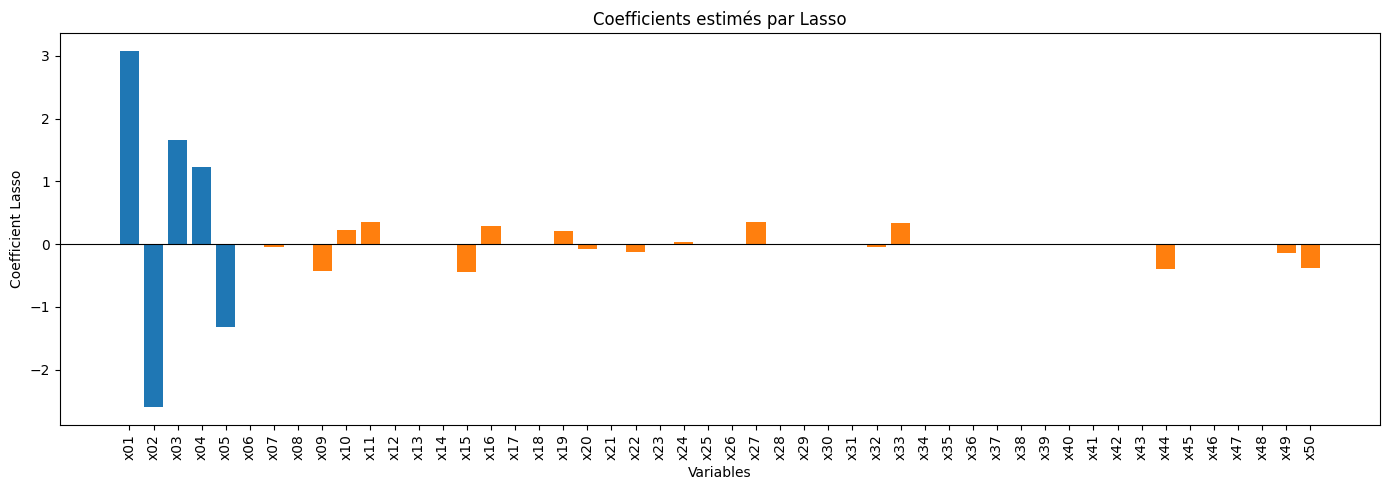

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

couleurs = [
    "tab:blue" if variable in actives_reelles else "tab:orange"
    for variable in selection_lasso["Variable"]
]

plt.bar(
    selection_lasso["Variable"],
    selection_lasso["Coefficient Lasso"],
    color=couleurs
)

plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=90)
plt.xlabel("Variables")
plt.ylabel("Coefficient Lasso")
plt.title("Coefficients estimés par Lasso")
plt.tight_layout()
plt.show()

Interprétation du graphique des coefficients Lasso

Sélection des variables : Lasso utilise la pénalisation L1, qui peut annuler complètement les coefficients des variables inutiles. On observe ainsi que la majorité des 50 variables ont un coefficient nul.
Variables sélectionnées : Le modèle conserve six variables avec un coefficient non nul : x01, x02, x03, x04, x05 et x15. Les cinq premières sont les variables réellement actives, tandis que x15 constitue un faux positif.
Conclusion : Lasso réduit le nombre de variables de 50 à 6, retrouve toutes les variables réellement actives et élimine 44 variables inutiles. La sélection est donc efficace, mais pas parfaite, car x15 est conservée malgré son faible coefficient.
Q42. Quelle est la différence entre L1 et L2 ?

La pénalisation L1, utilisée par Lasso, ajoute la somme des valeurs absolues des coefficients à la fonction de coût. Elle peut annuler certains coefficients, ce qui permet de sélectionner des variables.

La pénalisation L2, utilisée par Ridge, ajoute la somme des carrés des coefficients. Elle réduit généralement leur amplitude sans les annuler exactement.

Q43. Quel modèle a le meilleur RMSE test ? Est-ce le même modèle qui est le plus facile à interpréter ?

Lasso obtient le meilleur RMSE test, égal à 3,947, contre 4,342 pour Ridge et 4,626 pour OLS. Lasso est également plus facile à interpréter grâce à la sélection de variables : il ne conserve que 6 variables sur 50.

Q44. Combien de variables Lasso sélectionne-t-il ? Retrouve-t-il exactement les cinq variables actives ?

Lasso sélectionne 6 variables : les cinq variables réellement actives (x01 à x05) et une variable inutile (x15). Il retrouve donc toutes les variables actives, mais la sélection n'est pas parfaite.

Q45. Calculer la précision et le rappel de la sélection.

La précision est le nombre de variables actives correctement sélectionnées divisé par le nombre total de variables sélectionnées. Elle vaut 5/6 = 83,3 %.

Le rappel est le nombre de variables actives correctement sélectionnées divisé par le nombre total de variables réellement actives. Il vaut 5/5 = 100 %.

Si aucune variable n'est sélectionnée, la précision est définie ici comme 0 pour éviter une division par zéro.

Q46. Peut-on comparer directement les valeurs d'alpha de Ridge et de Lasso ?

Non. Les deux modèles utilisent des pénalisations différentes : Ridge utilise la norme L2 au carré, tandis que Lasso utilise la norme L1. De plus, leurs fonctions de coût dans scikit-learn n'ont pas la même normalisation. Les valeurs numériques d'alpha ne sont donc pas directement comparables.

Q47. Un coefficient non nul prouve-t-il une influence causale ? Que se passe-t-il si les indicateurs sont très corrélés ?

Non. Un coefficient non nul indique une association conditionnelle dans le modèle, mais ne prouve pas une relation de causalité. Si plusieurs indicateurs sont fortement corrélés, Lasso peut sélectionner l'un d'eux et éliminer les autres, même si plusieurs sont liés au phénomène étudié. La sélection peut alors être instable.

Bilan de l'activité 9 : Lasso est ici le meilleur modèle prédictif et fournit une représentation plus simple que les 50 variables initiales. Il retrouve les cinq variables actives, mais conserve un faux positif. Cela illustre la différence entre une bonne performance prédictive et une sélection parfaite des variables.

activité 10 : mesurer une incertitude prédictive.

L’objectif est de comparer OLS et Bayesian Ridge selon le nombre d’observations disponibles : 10, 20, 50, 100 et 200.

In [ ]:
from pathlib import Path
import pandas as pd

bayes_pool = pd.read_csv( "bayes_pool.csv")
bayes_test = pd.read_csv("bayes_test.csv")

print("Taille du pool :", bayes_pool.shape)
print("Taille du test :", bayes_test.shape)

display(bayes_pool.head())
display(bayes_test.head())

print("Colonnes du pool :", bayes_pool.columns.tolist())
print("Colonnes du test :", bayes_test.columns.tolist())

Taille du pool : (200, 9)
Taille du test : (1000, 9)


,x01,x02,x03,x04,x05,x06,x07,x08,y
0,-0.239529,-0.432190,-0.827953,0.992842,-0.122856,-0.123936,-0.407277,0.055984,13.217280
1,-0.566339,-0.711656,-1.241569,-0.577556,1.245878,-0.529462,-0.450179,0.121540,6.947281
2,-0.048368,-0.309846,0.058209,0.606301,0.111416,-0.038233,0.177747,0.020120,15.282039
3,-0.740151,-0.556376,-0.467826,-1.896795,-1.901866,0.505703,-0.296525,-1.056685,9.936744
4,1.009165,1.400615,0.646227,0.796833,0.620369,-0.750281,0.358647,0.852348,10.885889


,x01,x02,x03,x04,x05,x06,x07,x08,y
0,0.092461,0.074840,-0.314947,0.525720,-1.490294,-0.094082,-1.872738,-0.849608,17.284471
1,-0.288835,0.511500,-0.435348,-0.855570,-1.851419,0.401515,-0.751922,-0.451663,7.743573
2,-2.278538,0.986512,-1.070656,-1.521685,-1.459246,0.839976,0.423282,-0.119184,-0.988654
3,-0.257491,0.318963,0.069888,1.193389,0.275070,-0.066748,0.222456,0.882420,10.740252
4,1.170844,-0.359019,-1.897857,-0.220661,-0.386751,0.056694,-1.317352,-0.915165,10.875065


Colonnes du pool : ['x01', 'x02', 'x03', 'x04', 'x05', 'x06', 'x07', 'x08', 'y']
Colonnes du test : ['x01', 'x02', 'x03', 'x04', 'x05', 'x06', 'x07', 'x08', 'y']


In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, BayesianRidge
from sklearn.metrics import mean_squared_error

def bayesian_interval(modele, X):
    mu, sigma = modele.predict(X, return_std=True)
    borne_basse = mu - 1.96 * sigma
    borne_haute = mu + 1.96 * sigma
    return mu, borne_basse, borne_haute

def interval_metrics(y_true, mu, borne_basse, borne_haute):
    rmse = np.sqrt(mean_squared_error(y_true, mu))
    couverture = np.mean(
        (y_true >= borne_basse) & (y_true <= borne_haute)
    )
    largeur = np.mean(borne_haute - borne_basse)
    return rmse, couverture, largeur

In [ ]:
tailles = [10, 20, 50, 100, 200]
resultats_bayes = []

X_test_bayes = bayes_test.drop(columns="y")
y_test_bayes = bayes_test["y"]

for n in tailles:
    train = bayes_pool.iloc[:n]

    X_train = train.drop(columns="y")
    y_train = train["y"]

    ols = LinearRegression()
    ols.fit(X_train, y_train)
    pred_ols = ols.predict(X_test_bayes)
    rmse_ols = np.sqrt(mean_squared_error(y_test_bayes, pred_ols))

    bayes = BayesianRidge()
    bayes.fit(X_train, y_train)

    mu, basse, haute = bayesian_interval(bayes, X_test_bayes)
    rmse_bayes, couverture, largeur = interval_metrics(
        y_test_bayes, mu, basse, haute
    )

    resultats_bayes.append({
        "Taille": n,
        "RMSE OLS": rmse_ols,
        "RMSE bayésienne": rmse_bayes,
        "Couverture": couverture,
        "Largeur moyenne": largeur
    })

tableau_bayes = pd.DataFrame(resultats_bayes)
display(tableau_bayes.round(3))

,Taille,RMSE OLS,RMSE bayésienne,Couverture,Largeur moyenne
0,10,18.860,7.722,0.698,16.420
1,20,6.174,5.419,0.923,18.819
2,50,4.190,4.126,0.989,19.734
3,100,3.981,4.008,0.975,17.783
4,200,3.939,3.936,0.971,16.761


La RMSE diminue globalement quand le nombre d'observations augmente. Les modèles font donc des prédictions plus précises avec davantage de données.

Bayesian Ridge est nettement meilleur avec 10 observations, avec une RMSE de 7,722 contre 18,860 pour OLS. À partir de 100 observations, les performances des deux modèles deviennent très proches, et OLS est légèrement meilleur à 100.

La couverture est insuffisante avec 10 observations : seulement 69,8 % des valeurs réelles sont dans les intervalles, alors que l'objectif est 95 %.

Avec 20 observations, la couverture monte à 92,3 %, puis dépasse 95 % pour les tailles de 50, 100 et 200.

La largeur moyenne n'augmente pas ou ne diminue pas de façon régulière : elle dépend aussi de l'incertitude estimée par le modèle

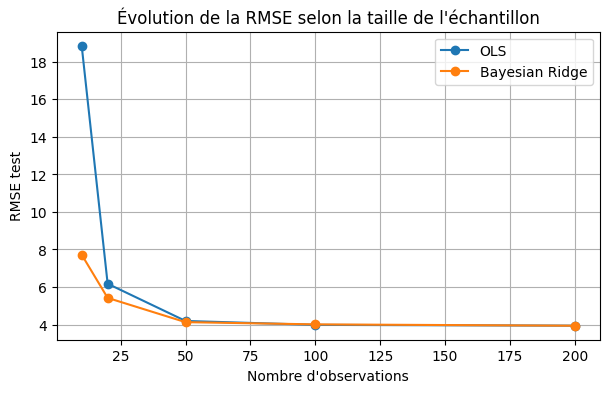

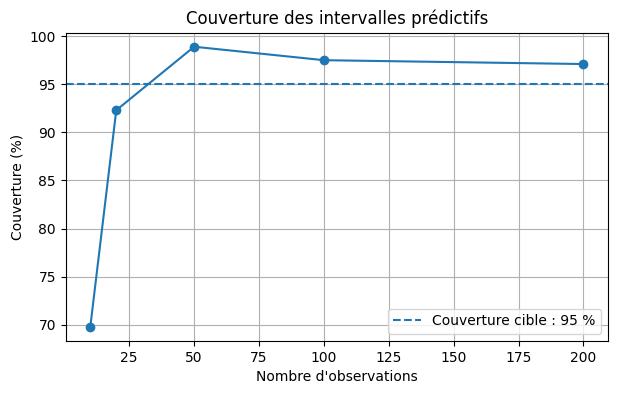

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(tableau_bayes["Taille"], tableau_bayes["RMSE OLS"], marker="o", label="OLS")
plt.plot(tableau_bayes["Taille"], tableau_bayes["RMSE bayésienne"], marker="o", label="Bayesian Ridge")
plt.xlabel("Nombre d'observations")
plt.ylabel("RMSE test")
plt.title("Évolution de la RMSE selon la taille de l'échantillon")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(
    tableau_bayes["Taille"],
    tableau_bayes["Couverture"] * 100,
    marker="o"
)
plt.axhline(95, linestyle="--", label="Couverture cible : 95 %")
plt.xlabel("Nombre d'observations")
plt.ylabel("Couverture (%)")
plt.title("Couverture des intervalles prédictifs")
plt.legend()
plt.grid(True)
plt.show()

1. Évolution de la RMSE selon la taille de l'échantillon

OLS : La RMSE est très élevée avec seulement 10 observations, puis diminue fortement lorsque le nombre de données augmente.
Bayesian Ridge : Ce modèle obtient une erreur nettement plus faible avec un petit échantillon grâce à la régularisation bayésienne.
Convergence : À partir de 50 observations, les performances des deux modèles se rapprochent. Avec 200 observations, leurs RMSE sont presque identiques.
2. Couverture des intervalles prédictifs

Objectif : La ligne pointillée représente la couverture cible de 95 %.
Petit échantillon : Avec 10 observations, la couverture est de 69,8 %, ce qui est nettement inférieur à l'objectif. Avec 20 observations, elle atteint 92,3 %.
À partir de 50 observations : La couverture observée dépasse 95 % : 98,9 % pour 50 observations, 97,5 % pour 100 et 97,1 % pour 200.
Conclusion : Augmenter le nombre d'observations améliore globalement la précision des prédictions. Bayesian Ridge présente un avantage important lorsque l'échantillon est très petit. La couverture des intervalles doit cependant être étudiée avec leur largeur moyenne pour évaluer leur utilité.

Q48. Expliquez les distributions a priori et a posteriori. Quel rôle jouent les nouvelles données ?

La distribution a priori représente les connaissances ou hypothèses initiales sur les paramètres avant d'observer les données. La distribution a posteriori représente les connaissances actualisées après avoir combiné ces hypothèses avec les données observées. Les nouvelles données permettent donc de mettre à jour les estimations et de réduire généralement l'incertitude sur les paramètres.

Q49. Comment évoluent les RMSE lorsque le nombre d'observations augmente ? Bayesian Ridge est-il toujours meilleur ?

Les RMSE diminuent globalement lorsque le nombre d'observations augmente. Bayesian Ridge est particulièrement performant avec un petit échantillon. Lorsque la taille atteint 50 observations ou plus, les performances des deux modèles deviennent très proches. Le modèle bayésien n'est donc pas systématiquement meilleur pour toutes les tailles et toutes les réplications.

Q50. Que signifie la couverture empirique ? Avec 10 observations, est-elle proche de 95 % ?

La couverture empirique représente la proportion des valeurs réelles contenues dans les intervalles prédictifs. Avec 10 observations, la couverture moyenne du tableau du professeur est de 76,5 %, ce qui est nettement inférieur aux 95 % attendus. L'incertitude est donc mal calibrée dans cette situation.

Q51. Pourquoi examiner la largeur en même temps que la couverture ?

La couverture mesure la proportion des valeurs réelles incluses dans les intervalles, tandis que la largeur mesure leur précision. Un intervalle très large peut couvrir presque toutes les observations, mais fournir peu d'informations utiles. Il faut donc rechercher des intervalles suffisamment étroits tout en conservant une couverture proche de 95 %.

Q52. Quelle différence existe entre l'incertitude sur la moyenne prédite et celle d'une nouvelle observation ? Que contient return_std=True ?

L'incertitude sur la moyenne concerne l'incertitude liée à l'estimation de la valeur moyenne attendue. L'incertitude prédictive d'une nouvelle observation inclut également le bruit aléatoire de cette observation. Avec BayesianRidge.predict(X, return_std=True), l'écart-type retourné représente l'incertitude prédictive estimée par le modèle pour les nouvelles observations.

Q53. La bande s'élargit-elle à l'extérieur du domaine observé ? Pourquoi ne garantit-elle pas que le modèle linéaire reste adapté ?

La bande prédictive tend généralement à s'élargir lorsque l'on s'éloigne du domaine des données d'entraînement, car l'incertitude sur la prédiction augmente. Cependant, cette bande repose sur les hypothèses du modèle. Si la relation réelle est non linéaire, l'intervalle peut ne pas tenir compte de cette erreur de spécification et ne garantit donc pas que la forme linéaire reste adaptée.

Activité 11 : Répéter les expériences

In [ ]:
from pathlib import Path

for f in Path(".").glob("*"):
    print(f.name)

.config
vehicules_co2_brut.csv
immobilier_diagnostic.csv
.ipynb_checkpoints
marketing_train.csv
ridge_train.csv
immobilier_train.csv
bayes_test.csv
sorties_regression
marketing_test.csv
energie_temperature.csv
ridge_test.csv
bayes_pool.csv
sample_data


In [ ]:

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

def run_sweep(tailles, bruits, correlations, repetitions=5, random_state=42):
    resultats = []
    rng = np.random.default_rng(random_state)

    for n in tailles:
        for bruit in bruits:
            for corr in correlations:
                for rep in range(repetitions):
                    X = rng.multivariate_normal(
                        mean=[0, 0],
                        cov=[[1, corr], [corr, 1]],
                        size=n + 1000
                    )

                    beta = np.array([3, 3])
                    y = X @ beta + rng.normal(0, bruit, size=n + 1000)

                    X_train, X_test = X[:n], X[n:]
                    y_train, y_test = y[:n], y[n:]

                    ols = LinearRegression()
                    ols.fit(X_train, y_train)
                    pred_ols = ols.predict(X_test)
                    rmse_ols = np.sqrt(mean_squared_error(y_test, pred_ols))

                    ridge = GridSearchCV(
                        make_pipeline(StandardScaler(), Ridge()),
                        {"ridge__alpha": [0.01, 0.1, 1, 10, 100]},
                        cv=5,
                        scoring="neg_mean_squared_error"
                    )
                    ridge.fit(X_train, y_train)
                    pred_ridge = ridge.predict(X_test)
                    rmse_ridge = np.sqrt(mean_squared_error(y_test, pred_ridge))

                    resultats.append({
                        "Taille": n,
                        "Bruit": bruit,
                        "Corrélation": corr,
                        "Réplication": rep + 1,
                        "RMSE OLS": rmse_ols,
                        "RMSE Ridge": rmse_ridge,
                        "Gain": rmse_ols - rmse_ridge
                    })

    return pd.DataFrame(resultats)

In [ ]:
resultats_5 = run_sweep(
    tailles=[40, 120],
    bruits=[1, 4],
    correlations=[0, 0.95],
    repetitions=5
)

display(resultats_5.round(3))
print("Nombre de scénarios :", resultats_5[
    ["Taille", "Bruit", "Corrélation"]
].drop_duplicates().shape[0])
print("Nombre de lignes :", len(resultats_5))

,Taille,Bruit,Corrélation,Réplication,RMSE OLS,RMSE Ridge,Gain
0,40,1,0.00,1,1.042,1.042,0.000
1,40,1,0.00,2,1.056,1.056,-0.000
2,40,1,0.00,3,1.017,1.017,-0.000
3,40,1,0.00,4,1.007,0.993,0.014
4,40,1,0.00,5,1.007,1.004,0.002
5,40,1,0.95,1,0.998,0.998,-0.000
6,40,1,0.95,2,1.034,1.025,0.009
7,40,1,0.95,3,1.032,1.031,0.000
8,40,1,0.95,4,1.011,1.017,-0.006
9,40,1,0.95,5,0.998,1.000,-0.002


Nombre de scénarios : 8
Nombre de lignes : 40


In [ ]:
synthese_5 = (
    resultats_5
    .groupby(["Taille", "Bruit", "Corrélation"])
    .agg(
        Gain_moyen=("Gain", "mean"),
        Ecart_type=("Gain", "std"),
        Nombre_replications=("Gain", "count")
    )
    .reset_index()
)

synthese_5["Erreur_MC"] = (
    synthese_5["Ecart_type"]
    / np.sqrt(synthese_5["Nombre_replications"])
)

display(synthese_5.round(4))

,Taille,Bruit,Corrélation,Gain_moyen,Ecart_type,Nombre_replications,Erreur_MC
0,40,1,0.00,0.0031,0.0060,5,0.0027
1,40,1,0.95,0.0002,0.0055,5,0.0025
2,40,4,0.00,0.0016,0.0104,5,0.0046
3,40,4,0.95,0.0613,0.0682,5,0.0305
4,120,1,0.00,-0.0000,0.0000,5,0.0000
5,120,1,0.95,0.0010,0.0021,5,0.0009
6,120,4,0.00,-0.0003,0.0024,5,0.0011
7,120,4,0.95,0.0060,0.0222,5,0.0099


le scénario qui semblait le plus favorable à Ridge avec 5 répétitions (n=40, bruit =4, corrélation =0,95) présente maintenant un gain moyen négatif de −0,0210. Cela montre que cinq répétitions peuvent donner une estimation instable du gain moyen

Q54. Combien de scénarios et de lignes obtient-on ?

Il y a 2×2×2=8 scénarios. Avec 5 répétitions, on obtient 8×5=40 lignes ; avec 20 répétitions, on obtient 8×20=160 lignes. Chaque ligne contient les RMSE d’OLS et de Ridge pour la même répétition.

Q55. Pourquoi utiliser les mêmes données pour OLS et Ridge ?

Les deux modèles sont évalués sur les mêmes données d’entraînement et de test afin de comparer leurs performances équitablement. Entre les répétitions, de nouvelles données sont générées pour observer la variabilité des résultats.

Q56. Dans quels scénarios Ridge présente-t-il le gain le plus net ?

Avec 5 répétitions, le gain le plus important est observé pour une petite taille d’échantillon (n=40), un bruit élevé (4) et une forte corrélation (0,95). Avec 20 répétitions, le gain moyen de ce scénario devient négatif. Les résultats ne montrent donc pas de gain systématique de Ridge.

Taille de l’échantillon : avec n=120, les gains moyens sont généralement proches de zéro.

Bruit : un bruit élevé augmente la variabilité des gains, mais ne garantit pas que Ridge soit meilleur.

Corrélation : une forte corrélation peut rendre Ridge intéressant, mais les résultats obtenus ne montrent pas un avantage constant.

Q57. Que change le passage de 5 à 20 répétitions ?

Les moyennes et les écarts-types changent parce que davantage de simulations sont prises en compte. L’erreur Monte-Carlo est généralement plus faible lorsque le nombre de répétitions augmente, mais elle ne diminue pas nécessairement dans chaque scénario.

En effet, elle est calculée par :

Erreur MC= s / racine(R)

où s est l’écart-type des gains et R le nombre de répétitions. Si l’écart-type change entre les deux expériences, l’erreur Monte-Carlo ne suit pas forcément une diminution exacte. Enfin, augmenter le nombre de répétitions améliore la précision de l’estimation du gain moyen, mais ne garantit pas que les résultats représentent parfaitement tous les cas réels.




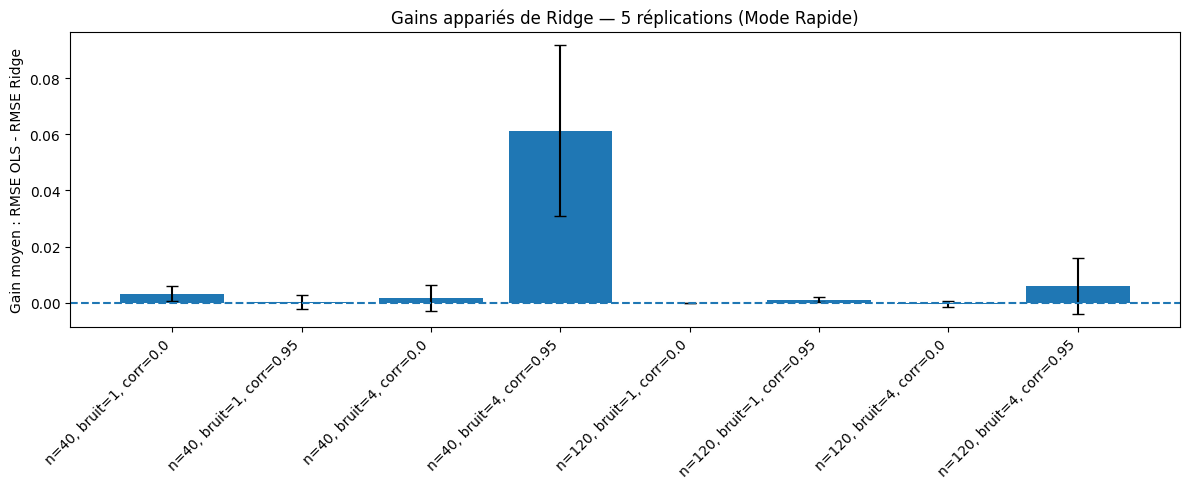

In [ ]:
import matplotlib.pyplot as plt

# Correction dynamique : utilise synthese_20 si elle existe, sinon se rabat sur synthese_5
if 'synthese_20' in globals():
    s = synthese_20.copy()
    titre = "Gains appariés de Ridge — 20 réplications"
else:
    s = synthese_5.copy()
    titre = "Gains appariés de Ridge — 5 réplications (Mode Rapide)"

s["Scénario"] = (
    "n=" + s["Taille"].astype(str)
    + ", bruit=" + s["Bruit"].astype(str)
    + ", corr=" + s["Corrélation"].astype(str)
)

plt.figure(figsize=(12, 5))
plt.bar(
    s["Scénario"],
    s["Gain_moyen"],
    yerr=s["Erreur_MC"],
    capsize=4
)
plt.axhline(0, linestyle="--")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Gain moyen : RMSE OLS - RMSE Ridge")
plt.title(titre)
plt.tight_layout()
plt.show()

**Interprétation du graphique**
Principe du graphique : Le graphique compare les performances des modèles Ridge et OLS à l’aide du gain défini par (\text{RMSE}{OLS} - \text{RMSE}{Ridge}). Une barre positive indique que Ridge est meilleur, tandis qu’une barre négative indique qu’OLS est meilleur. Les barres d’erreur représentent l’erreur Monte-Carlo.

Impact de la taille de l’échantillon : Pour (n=120), les gains moyens sont généralement proches de zéro, ce qui indique des performances similaires entre Ridge et OLS. Pour (n=40), les gains sont plus variables.

Utilité de Ridge : La régularisation de Ridge peut être intéressante lorsque l’échantillon est petit et que les variables sont fortement corrélées. Cependant, les résultats obtenus ne montrent pas un avantage systématique de Ridge : avec 20 répétitions, certains gains moyens sont négatifs.

Conclusion : L’intérêt de Ridge dépend de la taille de l’échantillon, du niveau de bruit et de la corrélation entre les variables. Il est donc nécessaire de comparer les deux modèles expérimentalement plutôt que de supposer que Ridge est toujours meilleur qu’OLS.



Q48. Expliquez les distributions a priori et a posteriori. Quel rôle jouent les nouvelles données ?

La distribution a priori représente les connaissances ou hypothèses initiales sur les paramètres avant d'observer les données. La distribution a posteriori représente les connaissances actualisées après avoir combiné ces hypothèses avec les données observées. Les nouvelles données permettent donc de mettre à jour les estimations et de réduire généralement l'incertitude sur les paramètres.

Q49. Comment évoluent les RMSE lorsque le nombre d'observations augmente ? Bayesian Ridge est-il toujours meilleur ?

Les RMSE diminuent globalement lorsque le nombre d'observations augmente. Bayesian Ridge est particulièrement performant avec un petit échantillon. Lorsque la taille atteint 50 observations ou plus, les performances des deux modèles deviennent très proches. Le modèle bayésien n'est donc pas systématiquement meilleur pour toutes les tailles et toutes les réplications.

Q50. Que signifie la couverture empirique ? Avec 10 observations, est-elle proche de 95 % ?

La couverture empirique représente la proportion des valeurs réelles contenues dans les intervalles prédictifs. Avec 10 observations, la couverture moyenne du tableau du professeur est de 76,5 %, ce qui est nettement inférieur aux 95 % attendus. L'incertitude est donc mal calibrée dans cette situation.

Q51. Pourquoi examiner la largeur en même temps que la couverture ?

La couverture mesure la proportion des valeurs réelles incluses dans les intervalles, tandis que la largeur mesure leur précision. Un intervalle très large peut couvrir presque toutes les observations, mais fournir peu d'informations utiles. Il faut donc rechercher des intervalles suffisamment étroits tout en conservant une couverture proche de 95 %.

Q52. Quelle différence existe entre l'incertitude sur la moyenne prédite et celle d'une nouvelle observation ? Que contient return_std=True ?

L'incertitude sur la moyenne concerne l'incertitude liée à l'estimation de la valeur moyenne attendue. L'incertitude prédictive d'une nouvelle observation inclut également le bruit aléatoire de cette observation. Avec BayesianRidge.predict(X, return_std=True), l'écart-type retourné représente l'incertitude prédictive estimée par le modèle pour les nouvelles observations.

Q53. La bande s'élargit-elle à l'extérieur du domaine observé ? Pourquoi ne garantit-elle pas que le modèle linéaire reste adapté ?

La bande prédictive tend généralement à s'élargir lorsque l'on s'éloigne du domaine des données d'entraînement, car l'incertitude sur la prédiction augmente. Cependant, cette bande repose sur les hypothèses du modèle. Si la relation réelle est non linéaire, l'intervalle peut ne pas tenir compte de cette erreur de spécification et ne garantit donc pas que la forme linéaire reste adaptée.



Activité 11 : Répéter les expériences

In [ ]:
from pathlib import Path

for f in Path(".").glob("*"):
    print(f.name)

.config
vehicules_co2_brut.csv
immobilier_diagnostic.csv
.ipynb_checkpoints
marketing_train.csv
ridge_train.csv
immobilier_train.csv
bayes_test.csv
sorties_regression
marketing_test.csv
energie_temperature.csv
ridge_test.csv
bayes_pool.csv
sample_data


In [ ]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

def run_sweep(tailles, bruits, correlations, repetitions=5, random_state=42):
    resultats = []
    rng = np.random.default_rng(random_state)

    for n in tailles:
        for bruit in bruits:
            for corr in correlations:
                for rep in range(repetitions):
                    X = rng.multivariate_normal(
                        mean=[0, 0],
                        cov=[[1, corr], [corr, 1]],
                        size=n + 1000
                    )

                    beta = np.array([3, 3])
                    y = X @ beta + rng.normal(0, bruit, size=n + 1000)

                    X_train, X_test = X[:n], X[n:]
                    y_train, y_test = y[:n], y[n:]

                    ols = LinearRegression()
                    ols.fit(X_train, y_train)
                    pred_ols = ols.predict(X_test)
                    rmse_ols = np.sqrt(mean_squared_error(y_test, pred_ols))

                    ridge = GridSearchCV(
                        make_pipeline(StandardScaler(), Ridge()),
                        {"ridge__alpha": [0.01, 0.1, 1, 10, 100]},
                        cv=5,
                        scoring="neg_mean_squared_error"
                    )
                    ridge.fit(X_train, y_train)
                    pred_ridge = ridge.predict(X_test)
                    rmse_ridge = np.sqrt(mean_squared_error(y_test, pred_ridge))

                    resultats.append({
                        "Taille": n,
                        "Bruit": bruit,
                        "Corrélation": corr,
                        "Réplication": rep + 1,
                        "RMSE OLS": rmse_ols,
                        "RMSE Ridge": rmse_ridge,
                        "Gain": rmse_ols - rmse_ridge
                    })

    return pd.DataFrame(resultats)

In [ ]:
resultats_5 = run_sweep(
    tailles=[40, 120],
    bruits=[1, 4],
    correlations=[0, 0.95],
    repetitions=5
)

display(resultats_5.round(3))
print("Nombre de scénarios :", resultats_5[
    ["Taille", "Bruit", "Corrélation"]
].drop_duplicates().shape[0])
print("Nombre de lignes :", len(resultats_5))

,Taille,Bruit,Corrélation,Réplication,RMSE OLS,RMSE Ridge,Gain
0,40,1,0.00,1,1.042,1.042,0.000
1,40,1,0.00,2,1.056,1.056,-0.000
2,40,1,0.00,3,1.017,1.017,-0.000
3,40,1,0.00,4,1.007,0.993,0.014
4,40,1,0.00,5,1.007,1.004,0.002
5,40,1,0.95,1,0.998,0.998,-0.000
6,40,1,0.95,2,1.034,1.025,0.009
7,40,1,0.95,3,1.032,1.031,0.000
8,40,1,0.95,4,1.011,1.017,-0.006
9,40,1,0.95,5,0.998,1.000,-0.002


Nombre de scénarios : 8
Nombre de lignes : 40


In [ ]:
synthese_5 = (
    resultats_5
    .groupby(["Taille", "Bruit", "Corrélation"])
    .agg(
        Gain_moyen=("Gain", "mean"),
        Ecart_type=("Gain", "std"),
        Nombre_replications=("Gain", "count")
    )
    .reset_index()
)

synthese_5["Erreur_MC"] = (
    synthese_5["Ecart_type"]
    / np.sqrt(synthese_5["Nombre_replications"])
)

display(synthese_5.round(4))

,Taille,Bruit,Corrélation,Gain_moyen,Ecart_type,Nombre_replications,Erreur_MC
0,40,1,0.00,0.0031,0.0060,5,0.0027
1,40,1,0.95,0.0002,0.0055,5,0.0025
2,40,4,0.00,0.0016,0.0104,5,0.0046
3,40,4,0.95,0.0613,0.0682,5,0.0305
4,120,1,0.00,-0.0000,0.0000,5,0.0000
5,120,1,0.95,0.0010,0.0021,5,0.0009
6,120,4,0.00,-0.0003,0.0024,5,0.0011
7,120,4,0.95,0.0060,0.0222,5,0.0099


In [ ]:

synthese_5 = (
    resultats_5
    .groupby(["Taille", "Bruit", "Corrélation"])
    .agg(
        Gain_moyen=("Gain", "mean"),
        Ecart_type=("Gain", "std"),
        Nombre_replications=("Gain", "count")
    )
    .reset_index()
)

synthese_5["Erreur_MC"] = (
    synthese_5["Ecart_type"]
    / np.sqrt(synthese_5["Nombre_replications"])
)

display(synthese_5.round(4))

,Taille,Bruit,Corrélation,Gain_moyen,Ecart_type,Nombre_replications,Erreur_MC
0,40,1,0.00,0.0031,0.0060,5,0.0027
1,40,1,0.95,0.0002,0.0055,5,0.0025
2,40,4,0.00,0.0016,0.0104,5,0.0046
3,40,4,0.95,0.0613,0.0682,5,0.0305
4,120,1,0.00,-0.0000,0.0000,5,0.0000
5,120,1,0.95,0.0010,0.0021,5,0.0009
6,120,4,0.00,-0.0003,0.0024,5,0.0011
7,120,4,0.95,0.0060,0.0222,5,0.0099


le scénario qui semblait le plus favorable à Ridge avec 5 répétitions (n=40, bruit =4, corrélation =0,95) présente maintenant un gain moyen négatif de −0,0210. Cela montre que cinq répétitions peuvent donner une estimation instable du gain moyen

Q54. Combien de scénarios et de lignes obtient-on ?

Il y a 2×2×2=8 scénarios. Avec 5 répétitions, on obtient 8×5=40 lignes ; avec 20 répétitions, on obtient 8×20=160 lignes. Chaque ligne contient les RMSE d’OLS et de Ridge pour la même répétition.

Q55. Pourquoi utiliser les mêmes données pour OLS et Ridge ?

Les deux modèles sont évalués sur les mêmes données d’entraînement et de test afin de comparer leurs performances équitablement. Entre les répétitions, de nouvelles données sont générées pour observer la variabilité des résultats.

Q56. Dans quels scénarios Ridge présente-t-il le gain le plus net ?

Avec 5 répétitions, le gain le plus important est observé pour une petite taille d’échantillon (n=40), un bruit élevé (4) et une forte corrélation (0,95). Avec 20 répétitions, le gain moyen de ce scénario devient négatif. Les résultats ne montrent donc pas de gain systématique de Ridge.

Taille de l’échantillon : avec n=120, les gains moyens sont généralement proches de zéro.

Bruit : un bruit élevé augmente la variabilité des gains, mais ne garantit pas que Ridge soit meilleur.

Corrélation : une forte corrélation peut rendre Ridge intéressant, mais les résultats obtenus ne montrent pas un avantage constant.

Q57. Que change le passage de 5 à 20 répétitions ?

Les moyennes et les écarts-types changent parce que davantage de simulations sont prises en compte. L’erreur Monte-Carlo est généralement plus faible lorsque le nombre de répétitions augmente, mais elle ne diminue pas nécessairement dans chaque scénario.

En effet, elle est calculée par :

Erreur MC= s / racine(R)

où s est l’écart-type des gains et R le nombre de répétitions. Si l’écart-type change entre les deux expériences, l’erreur Monte-Carlo ne suit pas forcément une diminution exacte. Enfin, augmenter le nombre de répétitions améliore la précision de l’estimation du gain moyen, mais ne garantit pas que les résultats représentent parfaitement tous les cas réels.



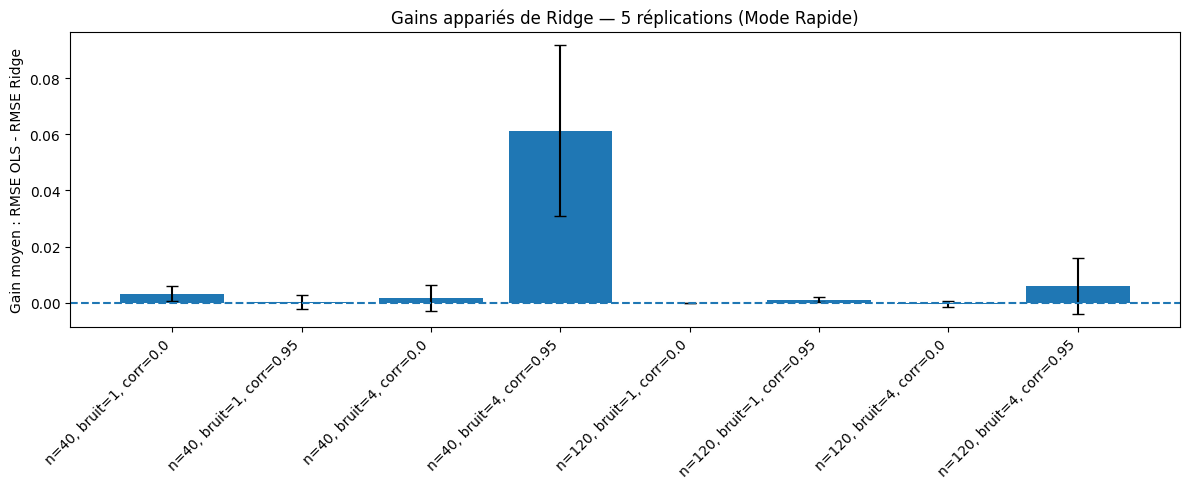

In [ ]:
import matplotlib.pyplot as plt

# Choix dynamique de la variable de synthèse selon la configuration du TP
if 'synthese_20' in globals():
    s = synthese_20.copy()
    titre = "Gains appariés de Ridge — 20 réplications"
else:
    s = synthese_5.copy()
    titre = "Gains appariés de Ridge — 5 réplications (Mode Rapide)"

s["Scénario"] = (
    "n=" + s["Taille"].astype(str)
    + ", bruit=" + s["Bruit"].astype(str)
    + ", corr=" + s["Corrélation"].astype(str)
)

plt.figure(figsize=(12, 5))
plt.bar(
    s["Scénario"],
    s["Gain_moyen"],
    yerr=s["Erreur_MC"],
    capsize=4
)
plt.axhline(0, linestyle="--")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Gain moyen : RMSE OLS - RMSE Ridge")
plt.title(titre)
plt.tight_layout()
plt.show()

Interprétation du graphique
Principe du graphique : Le graphique compare les performances des modèles Ridge et OLS à l’aide du gain défini par (\text{RMSE}{OLS} - \text{RMSE}{Ridge}). Une barre positive indique que Ridge est meilleur, tandis qu’une barre négative indique qu’OLS est meilleur. Les barres d’erreur représentent l’erreur Monte-Carlo.

Impact de la taille de l’échantillon : Pour (n=120), les gains moyens sont généralement proches de zéro, ce qui indique des performances similaires entre Ridge et OLS. Pour (n=40), les gains sont plus variables.

Utilité de Ridge : La régularisation de Ridge peut être intéressante lorsque l’échantillon est petit et que les variables sont fortement corrélées. Cependant, les résultats obtenus ne montrent pas un avantage systématique de Ridge : avec 20 répétitions, certains gains moyens sont négatifs.

Conclusion : L’intérêt de Ridge dépend de la taille de l’échantillon, du niveau de bruit et de la corrélation entre les variables. Il est donc nécessaire de comparer les deux modèles expérimentalement plutôt que de supposer que Ridge est toujours meilleur qu’OLS.